# ¿Cómo se usan los aviones widebody en las rutas del mundo?

**Proyecto final de Ciencia de Datos, curso Data Xperience.** Integrante: Danilo Rocha Medina.

Este notebook analiza en qué rutas vuelan seis familias de aviones de fuselaje ancho (*widebody*): A380, Boeing 747, A350, Boeing 777, A330 y Boeing 787.

**Las dos fuentes y por qué hay dos:**

| | OpenFlights (principal) | OpenSky (complementaria) |
|---|---|---|
| Qué contiene | Rutas publicadas por aerolínea | Vuelos observados por antenas ADS-B |
| Fecha | Hasta junio de 2014 | Octubre de 2019 |
| Familias | A380, 747, 777, A330, 787 | Las seis, incluido el A350 |

El A350 **no tiene ninguna ruta en OpenFlights**, porque esa base dejó de actualizarse en junio de 2014. Por eso se analiza con OpenSky en una sección aparte. Las dos fuentes miden cosas distintas, así que **sus conteos no se comparan entre sí**.

# Etapa 1: Fundamentos

## 1.1 Justificación del dataset y relación con la carrera

**¿Por qué estos datos?** OpenFlights es una base pública muy usada, con cuatro tablas relacionadas: rutas, aeropuertos, aerolíneas y aviones. Permite responder una pregunta concreta sobre un tema que me apasiona, la aviación de largo alcance, con datos verificables.

**¿Qué tiene que ver con Ingeniería de Sistemas?** Este trabajo es muy parecido al de un sistema de información real:

- **Modelo de datos:** las tablas se relacionan mediante identificadores, igual que en una base de datos relacional.
- **Calidad de datos:** hay nulos, códigos ambiguos y campos con varios valores en una sola celda.
- **Integración de fuentes:** se unen tablas y fuentes con códigos distintos (IATA e ICAO).
- **Reproducibilidad:** cualquiera puede ejecutar este notebook y obtener los mismos resultados desde los archivos originales.

## 1.2 Preparación

Esta celda carga las librerías y decide de dónde leer los datos. Si el notebook está junto a la carpeta `datos/`, los lee de ahí. Si se ejecuta en Google Colab, los lee de la URL *raw* del repositorio de GitHub.

**En Colab:** comprueba que `GITHUB_USUARIO` tenga el usuario de GitHub dueño del repositorio.

In [ ]:
from pathlib import Path
from urllib.parse import quote

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.collections import LineCollection
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from matplotlib.ticker import FuncFormatter
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder

GITHUB_USUARIO = "DanEan-ux"
GITHUB_REPO = "ProyectoFinalDataExperiencie"
GITHUB_RAMA = "main"

if Path("../datos/routes.dat").exists():
    DATOS = "../datos/"
    SALIDA = Path("../datos")
    FIGURAS = Path("../presentacion/figuras")
else:
    if GITHUB_USUARIO == "TU_USUARIO":
        raise ValueError("Cambia GITHUB_USUARIO por tu usuario de GitHub para leer los datos desde el repositorio.")
    DATOS = f"https://raw.githubusercontent.com/{GITHUB_USUARIO}/{quote(GITHUB_REPO)}/{GITHUB_RAMA}/datos/"
    SALIDA = Path("datos_limpios")
    FIGURAS = Path("figuras")
SALIDA.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

AZUL, NARANJA, GRIS = "#2a78d6", "#eb6834", "#c3c2b7"
SEMILLA = 42
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e", "axes.titlecolor": "#0b0b0b",
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.7, "axes.axisbelow": True,
    "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": "#0b0b0b",
    "legend.frameon": False, "font.size": 10,
})
miles = FuncFormatter(lambda x, _: f"{x:,.0f}".replace(",", "."))
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)

def guardar(fig, nombre):
    fig.savefig(FIGURAS / nombre, dpi=150, bbox_inches="tight")
    plt.show()

print("Leyendo datos desde:", DATOS)

Leyendo datos desde: ../datos/


## 1.3 Carga de los archivos

Los archivos `.dat` **no traen encabezado**, así que los nombres de las columnas se toman de la [documentación de OpenFlights](https://openflights.org/data.php). Dos detalles importantes al leerlos:

- `\N` significa nulo, y se lo indico a pandas.
- Se usa `keep_default_na=False` para decidir yo qué cuenta como nulo. Sin esto, pandas también convertiría en nulos textos como `NA` o `None`, que en una tabla de códigos podrían ser valores reales.

In [ ]:
def leer_dat(archivo, columnas):
    return pd.read_csv(DATOS + archivo, header=None, names=columnas, na_values=["\\N"], keep_default_na=False, encoding="utf-8")

rutas = leer_dat("routes.dat", ["aerolinea_cod", "aerolinea_id", "origen", "origen_id", "destino", "destino_id", "codigo_compartido", "escalas", "equipo"])
aeropuertos = leer_dat("airports.dat", ["aeropuerto_id", "nombre", "ciudad", "pais", "iata", "icao", "latitud", "longitud", "altitud", "utc", "dst", "tz", "tipo", "fuente"])
aerolineas = leer_dat("airlines.dat", ["aerolinea_id", "nombre", "alias", "iata", "icao", "indicativo", "pais", "activa"])
aviones = leer_dat("planes.dat", ["nombre", "iata", "icao"])

tablas = {"routes.dat": rutas, "airports.dat": aeropuertos, "airlines.dat": aerolineas, "planes.dat": aviones}
display(pd.DataFrame({n: {"filas": d.shape[0], "columnas": d.shape[1]} for n, d in tablas.items()}).T)
display(rutas.head())

,filas,columnas
routes.dat,67663,9
airports.dat,7698,14
airlines.dat,6162,8
planes.dat,246,3


,aerolinea_cod,aerolinea_id,origen,origen_id,destino,destino_id,codigo_compartido,escalas,equipo
0,2B,410.0,AER,2965.0,KZN,2990.0,,0,CR2
1,2B,410.0,ASF,2966.0,KZN,2990.0,,0,CR2
2,2B,410.0,ASF,2966.0,MRV,2962.0,,0,CR2
3,2B,410.0,CEK,2968.0,KZN,2990.0,,0,CR2
4,2B,410.0,CEK,2968.0,OVB,4078.0,,0,CR2


## 1.4 Exploración

Primero miro la estructura de cada tabla: qué columnas tiene, de qué tipo es cada una y cuántos valores le faltan.

**Tipos de variable que aparecen:**

- **Categóricas nominales:** aerolínea, aeropuerto, país y código de avión.
- **Numéricas continuas:** latitud, longitud y, más adelante, distancia.
- **Numéricas discretas:** número de escalas.
- **Identificadores:** son números, pero no tiene sentido promediarlos, como `aerolinea_id`.

In [ ]:
for nombre, tabla in tablas.items():
    print(f"\n===== {nombre} =====")
    tabla.info()


===== routes.dat =====
<class 'pandas.DataFrame'>
RangeIndex: 67663 entries, 0 to 67662
Data columns (total 9 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   aerolinea_cod      67663 non-null  str    
 1   aerolinea_id       67184 non-null  float64
 2   origen             67663 non-null  str    
 3   origen_id          67443 non-null  float64
 4   destino            67663 non-null  str    
 5   destino_id         67442 non-null  float64
 6   codigo_compartido  67663 non-null  str    
 7   escalas            67663 non-null  int64  
 8   equipo             67663 non-null  str    
dtypes: float64(3), int64(1), str(5)
memory usage: 4.6 MB

===== airports.dat =====
<class 'pandas.DataFrame'>
RangeIndex: 7698 entries, 0 to 7697
Data columns (total 14 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   aeropuerto_id  7698 non-null   int64  
 1   nombre         7698 non-null   str

In [ ]:
# Un campo puede estar marcado como nulo (\N) o simplemente vacío: se cuentan por separado.
resumen = []
for nombre, tabla in tablas.items():
    for col in tabla.columns:
        resumen.append({"archivo": nombre, "columna": col, "nulos_N": tabla[col].isna().sum(), "vacios": (tabla[col] == "").sum()})
resumen = pd.DataFrame(resumen)
display(resumen[(resumen.nulos_N > 0) | (resumen.vacios > 0)].reset_index(drop=True))
display(pd.DataFrame({n: {"duplicados_exactos": d.duplicated().sum()} for n, d in tablas.items()}).T)

,archivo,columna,nulos_N,vacios
0,routes.dat,aerolinea_id,479,0
1,routes.dat,origen_id,220,0
2,routes.dat,destino_id,221,0
3,routes.dat,codigo_compartido,0,53066
4,routes.dat,equipo,0,18
5,airports.dat,ciudad,0,49
6,airports.dat,iata,1626,0
7,airports.dat,icao,1,0
8,airports.dat,utc,353,0
9,airports.dat,dst,353,0


,duplicados_exactos
routes.dat,0
airports.dat,0
airlines.dat,0
planes.dat,0


Escalas: {0: 67652, 1: 11}
Código compartido: {'No marcado': 53066, 'Y': 14597}
Valores de 'activa' en aerolíneas: {'N': 4906, 'Y': 1255, 'n': 1}


Rutas con más de un avión en 'equipo': 17129


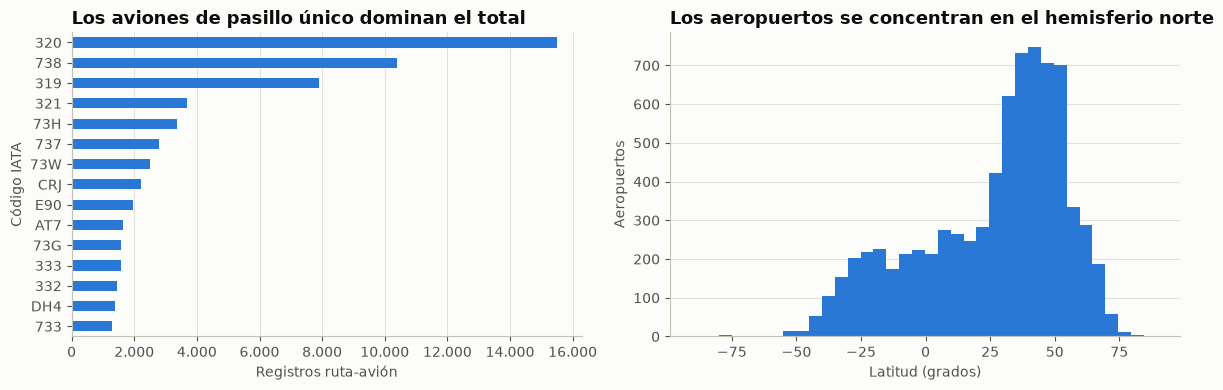

In [ ]:
print("Escalas:", rutas["escalas"].value_counts().to_dict())
print("Código compartido:", rutas["codigo_compartido"].replace("", "No marcado").value_counts().to_dict())
print("Valores de 'activa' en aerolíneas:", aerolineas["activa"].value_counts().to_dict())
print("Rutas con más de un avión en 'equipo':", (rutas["equipo"].str.split().str.len() > 1).sum())

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
rutas["equipo"].str.split().explode().value_counts().head(15).sort_values().plot.barh(ax=ejes[0], color=AZUL)
ejes[0].set(title="Los aviones de pasillo único dominan el total", xlabel="Registros ruta-avión", ylabel="Código IATA")
ejes[0].xaxis.set_major_formatter(miles)
aeropuertos["latitud"].plot.hist(bins=36, ax=ejes[1], color=AZUL)
ejes[1].set(title="Los aeropuertos se concentran en el hemisferio norte", xlabel="Latitud (grados)", ylabel="Aeropuertos")
ejes[0].grid(axis="y", visible=False)
ejes[1].grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

**Qué veo en la exploración:**

- **Sin duplicados exactos** en ninguna de las cuatro tablas.
- **Una celda, varios aviones:** 17.129 de las 67.663 rutas (25,3 %) tienen más de un avión en `equipo`, así que hay que separarlos.
- **Código compartido:** 14.597 rutas (21,6 %) están marcadas como tal, es decir, la aerolínea listada no opera el vuelo.
- **Escalas:** solo 11 rutas tienen alguna.
- **Faltantes de dos tipos:** además de `\N`, hay campos vacíos, como 18 rutas sin `equipo`.
- **Formato inconsistente:** una aerolínea tiene `activa` como `n` en minúscula.
- **Aviones:** los códigos más frecuentes, como `320`, `738` y `319`, son de pasillo único. Los widebody son una parte pequeña del total, por eso hay que filtrarlos.
- **Geografía:** los aeropuertos se concentran entre los 25° y 60° de latitud norte.

## 1.5 ¿Existen los códigos de avión?

Antes de filtrar, compruebo cuántos registros tiene cada código. Muchos vienen en forma específica (`77W`) y otros en forma genérica (`777`), de modo que usar solo los primeros dejaría fuera rutas reales. Por eso se analiza por **familia**.

Se excluyen `74Y`, `74N`, `33X` y `77X`, porque el análisis se centra en pasajeros y, hasta donde sé, son versiones de carga. Es un supuesto mío: `planes.dat` no incluye esos códigos.

In [ ]:
CODIGOS_FAMILIA = {
    "A380": ["388", "380"],
    "747": ["744", "74H", "747", "74E", "74M", "74L"],
    "A350": ["359", "35K"],
    "777": ["77W", "773", "777", "772", "77L"],
    "A330": ["332", "333", "330"],
    "787": ["788", "789", "787"],
}
CARGUEROS = ["74Y", "74N", "33X", "77X"]
FAMILIA = {c: f for f, lista in CODIGOS_FAMILIA.items() for c in lista}

equipo = rutas.assign(codigo=rutas["equipo"].str.split()).explode("codigo")
conteo = equipo["codigo"].value_counts()
nombres = aviones.dropna(subset=["iata"]).set_index("iata")["nombre"]
tabla_codigos = pd.DataFrame(
    [{"familia": FAMILIA.get(c, "excluido (carga)"), "codigo": c, "registros": int(conteo.get(c, 0)), "nombre_planes_dat": nombres.get(c, "no aparece")}
     for c in list(FAMILIA) + CARGUEROS]
)
display(tabla_codigos)
print("Códigos de 'equipo' que empiezan por 35:", sorted(c for c in conteo.index if c.startswith("35")))

,familia,codigo,registros,nombre_planes_dat
0,A380,388,214,Airbus A380-800
1,A380,380,28,Airbus A380
2,747,744,603,Boeing 747-400
3,747,74H,22,no aparece
4,747,747,62,Boeing 747
5,747,74E,61,no aparece
6,747,74M,38,no aparece
7,747,74L,6,Boeing 747SP
8,A350,359,0,Airbus A350-900
9,A350,35K,0,no aparece


Códigos de 'equipo' que empiezan por 35: []


**Resultado clave:** `359`, `35K` y `789` tienen **0 registros**. No es un error de lectura: ningún código de `equipo` empieza por `35`. OpenFlights no contiene el A350 porque sus rutas llegan hasta junio de 2014. Por eso esta parte del análisis usa cinco familias, y el A350 se estudia más adelante con OpenSky.

## 1.6 Limpieza y unión de tablas

| Problema detectado | Decisión | Por qué |
|---|---|---|
| Varios aviones en una misma celda de `equipo` | Separar en una fila por avión | Para contar cada modelo |
| Vuelos en código compartido | Quitarlos | La aerolínea listada no opera el vuelo, así que la ruta se contaría dos veces |
| Rutas con escalas | Quitarlas | La distancia directa entre origen y destino no representaría el trayecto |
| `origen_id` o `destino_id` nulos | Recuperarlos con el código IATA | Se conservan rutas válidas |
| Identificadores sin aeropuerto en `airports.dat` | Quitarlos | Sin coordenadas no se puede calcular la distancia |
| Aerolínea sin identificador | Marcarla como `Sin identificar` | La distancia sigue siendo válida |
| Misma ruta con dos variantes (por ejemplo, `332` y `333`) | Dejar una fila por familia | Para no contar dos veces la misma ruta |
| `activa` con `n` en minúscula | Pasar a mayúsculas | Unifica el formato |
| Textos vacíos | Convertir a nulo | Todos los faltantes quedan iguales |
| Aeropuertos sin zona horaria (`tz`), como Doha | Tomar la región más común de su país | La región se usa después en el modelo |

In [ ]:
embudo = [("Filas originales de routes.dat", len(rutas))]

aerolineas["activa"] = aerolineas["activa"].str.upper()
aerolineas = aerolineas.replace("", np.nan)
aeropuertos = aeropuertos.replace("", np.nan)

widebody = equipo[equipo["codigo"].isin(FAMILIA)].copy()
widebody["familia"] = widebody["codigo"].map(FAMILIA)
embudo.append(("Registros ruta-avión widebody", len(widebody)))

widebody = widebody[widebody["codigo_compartido"] != "Y"]
embudo.append(("Sin código compartido", len(widebody)))

widebody = widebody[widebody["escalas"] == 0]
embudo.append(("Sin escalas", len(widebody)))

iata_a_id = aeropuertos.dropna(subset=["iata"]).drop_duplicates("iata").set_index("iata")["aeropuerto_id"]
recuperados = widebody["origen_id"].isna().sum() + widebody["destino_id"].isna().sum()
widebody["origen_id"] = widebody["origen_id"].fillna(widebody["origen"].map(iata_a_id))
widebody["destino_id"] = widebody["destino_id"].fillna(widebody["destino"].map(iata_a_id))
print("Identificadores nulos antes de recuperar:", recuperados, "| después:", widebody["origen_id"].isna().sum() + widebody["destino_id"].isna().sum())

aeropuertos["region"] = aeropuertos["tz"].str.split("/").str[0]
region_pais = aeropuertos.dropna(subset=["region"]).groupby("pais")["region"].agg(lambda s: s.mode().iloc[0])
sin_region = aeropuertos["region"].isna().sum()
aeropuertos["region"] = aeropuertos["region"].fillna(aeropuertos["pais"].map(region_pais)).fillna("Desconocida")
print("Aeropuertos sin zona horaria:", sin_region, "| siguen sin región:", (aeropuertos["region"] == "Desconocida").sum())

columnas_aeropuerto = ["aeropuerto_id", "nombre", "ciudad", "pais", "latitud", "longitud", "region"]
def con_aeropuertos(df, col_origen, col_destino):
    orig = aeropuertos[columnas_aeropuerto].add_suffix("_origen")
    dest = aeropuertos[columnas_aeropuerto].add_suffix("_destino")
    return df.merge(orig, left_on=col_origen, right_on="aeropuerto_id_origen").merge(dest, left_on=col_destino, right_on="aeropuerto_id_destino")

datos = con_aeropuertos(widebody, "origen_id", "destino_id")
embudo.append(("Con ambos aeropuertos en airports.dat", len(datos)))

datos = datos.merge(aerolineas[["aerolinea_id", "nombre", "pais"]].rename(columns={"nombre": "aerolinea", "pais": "pais_aerolinea"}), on="aerolinea_id", how="left")
datos["aerolinea"] = datos["aerolinea"].fillna("Sin identificar")
print("Filas con aerolínea sin identificar:", (datos["aerolinea"] == "Sin identificar").sum())

def agregar_contexto(df):
    df["tipo_ruta"] = np.where(df["pais_origen"] == df["pais_destino"], "Doméstica", "Internacional")
    return df

datos = agregar_contexto(datos)
variantes = datos.copy()
limpio = datos.drop_duplicates(["aerolinea_cod", "origen", "destino", "familia"]).reset_index(drop=True)
embudo.append(("Una fila por aerolínea, ruta y familia", len(limpio)))

display(pd.DataFrame(embudo, columns=["paso", "filas"]))
print("Nulos en las columnas de análisis:", limpio[["familia", "origen", "destino", "latitud_origen", "longitud_origen", "latitud_destino", "longitud_destino"]].isna().sum().sum())
print("Duplicados:", limpio.duplicated(["aerolinea_cod", "origen", "destino", "familia"]).sum())

Identificadores nulos antes de recuperar: 17 | después: 0
Aeropuertos sin zona horaria: 1021 | siguen sin región: 0
Filas con aerolínea sin identificar: 6


,paso,filas
0,Filas originales de routes.dat,67663
1,Registros ruta-avión widebody,8376
2,Sin código compartido,6420
3,Sin escalas,6419
4,Con ambos aeropuertos en airports.dat,6417
5,"Una fila por aerolínea, ruta y familia",5841


Nulos en las columnas de análisis: 0
Duplicados: 0


### Tabla resumen del dataset depurado

Cada fila del dataset limpio es una combinación de **aerolínea, origen, destino y familia**. Una ruta de ida y su vuelta cuentan como dos filas, porque así aparecen en `routes.dat`.

In [ ]:
resumen_limpio = limpio.groupby("familia").agg(
    rutas=("origen", "size"),
    aerolineas=("aerolinea_cod", "nunique"),
    aeropuertos_origen=("origen", "nunique"),
    paises_origen=("pais_origen", "nunique"),
    pct_internacional=("tipo_ruta", lambda s: round((s == "Internacional").mean() * 100, 1)),
).sort_values("rutas", ascending=False)
display(resumen_limpio)
print(f"Total: {len(limpio):,} filas | {limpio['aerolinea_cod'].nunique()} aerolíneas | {pd.concat([limpio['origen'], limpio['destino']]).nunique()} aeropuertos".replace(",", "."))

,rutas,aerolineas,aeropuertos_origen,paises_origen,pct_internacional
familia,,,,,
A330,2762,99,324,133,90.6
777,2030,56,226,102,92.6
747,550,32,129,57,94.5
787,320,25,100,46,82.2
A380,179,16,36,23,98.9


Total: 5.841 filas | 123 aerolíneas | 383 aeropuertos


**Qué dice la tabla:** de 8.376 registros widebody quedan 5.841 filas confiables. La mayor reducción viene de quitar 1.956 registros de código compartido (23,4 %). El A330 y el 777 suman 4.792 filas, el 82 % del total. El A380 es casi exclusivamente internacional (98,9 %), mientras que el 787 tiene la mayor proporción de rutas domésticas (17,8 %).

# Etapa 2: Estadística descriptiva

## 2.1 Distancia de cada ruta con la fórmula haversine

La Tierra es casi una esfera, así que la distancia entre dos aeropuertos no es una línea recta sobre un mapa. La **fórmula haversine** calcula la distancia más corta sobre la superficie de una esfera a partir de las latitudes y longitudes:

$$d = 2R \cdot \arcsin\left(\sqrt{\sin^2\left(\frac{\Delta\phi}{2}\right) + \cos\phi_1 \cos\phi_2 \sin^2\left(\frac{\Delta\lambda}{2}\right)}\right)$$

Donde $R$ = 6.371 km es el radio medio de la Tierra, $\phi$ es la latitud y $\lambda$ la longitud. El resultado es la distancia teórica mínima: un vuelo real recorre algo más, por vientos o corredores aéreos.

In [ ]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 6371.0 * np.arcsin(np.sqrt(a))

def agregar_distancia(df):
    df["km"] = haversine(df["latitud_origen"], df["longitud_origen"], df["latitud_destino"], df["longitud_destino"])
    return df

limpio = agregar_distancia(limpio)
variantes = agregar_distancia(variantes)

# Comprobación: Londres Heathrow a Nueva York JFK es una ruta conocida de unos 5.500 km.
ejemplo = limpio[(limpio["origen"] == "LHR") & (limpio["destino"] == "JFK")]["km"].iloc[0]
print(f"LHR-JFK: {ejemplo:,.0f} km".replace(",", "."))

columnas_csv = ["aerolinea_cod", "aerolinea", "pais_aerolinea", "origen", "ciudad_origen", "pais_origen", "latitud_origen", "longitud_origen",
                "destino", "ciudad_destino", "pais_destino", "latitud_destino", "longitud_destino", "region_origen", "region_destino", "tipo_ruta", "familia", "km"]
limpio[columnas_csv].round({"km": 1}).to_csv(SALIDA / "rutas_widebody_limpio.csv", index=False, encoding="utf-8")
print("Guardado:", SALIDA / "rutas_widebody_limpio.csv", limpio[columnas_csv].shape)

LHR-JFK: 5.540 km
Guardado: ..\datos\rutas_widebody_limpio.csv (5841, 18)


## 2.2 Medidas por tipo de avión

**Cómo leer la tabla:**

- **Media:** el promedio. Le afectan las rutas muy cortas o muy largas.
- **Mediana:** la mitad de las rutas son más cortas que este valor. Es la medida más robusta aquí.
- **Moda:** el valor más repetido. Como la distancia casi nunca se repite exacta, se redondea a múltiplos de 100 km.
- **Rango:** la diferencia entre la ruta más larga y la más corta.
- **Varianza y desviación estándar:** qué tan dispersas están las rutas. La desviación está en km; la varianza, en km².

In [ ]:
def estadisticos(df, col="km"):
    g = df.groupby("familia")[col]
    t = g.agg(n="count", media="mean", mediana="median", minimo="min", maximo="max", varianza="var", desv_est="std")
    t["moda_100km"] = g.apply(lambda s: s.round(-2).mode().iloc[0])
    t["rango"] = t["maximo"] - t["minimo"]
    return t[["n", "media", "mediana", "moda_100km", "minimo", "maximo", "rango", "varianza", "desv_est"]].sort_values("mediana", ascending=False)

est_of = estadisticos(limpio)
display(est_of.round(0).astype(int))

print("Por variante de código (solo códigos con al menos 30 registros):")
est_var = variantes.groupby("codigo")["km"].agg(n="count", media="mean", mediana="median", desv_est="std")
display(est_var[est_var["n"] >= 30].sort_values("mediana", ascending=False).round(0).astype(int))

,n,media,mediana,moda_100km,minimo,maximo,rango,varianza,desv_est
familia,,,,,,,,,
A380,179,7686,8403,10300,1689,13400,11711,9264767,3044
747,550,5861,6591,800,120,13808,13688,11249359,3354
777,2030,6113,6177,9600,100,13583,13482,12171719,3489
787,320,5376,5707,400,26,11563,11537,11137234,3337
A330,2762,4265,4204,700,136,10085,9949,7104429,2665


Por variante de código (solo códigos con al menos 30 registros):


,n,media,mediana,desv_est
codigo,,,,
388,159,7610,7764,3011
747,36,6042,7224,3189
777,683,6510,6724,3283
744,433,5917,6627,3417
77W,714,6426,6200,3449
77L,118,6916,6044,3974
788,229,5501,5784,3001
787,91,5062,5513,4065
332,1113,4491,4651,2702


**Interpretación:**

- **El A380 vuela las rutas más largas:** su mediana es de 8.403 km, el doble que la del A330 (4.204 km), que tiene la más baja.
- **Mediana mayor que la media en A380 y 747:** la mayoría de sus rutas son largas, pero un grupo de rutas cortas baja el promedio.
- **Un widebody no siempre vuela lejos:** la moda del 787 es 400 km, la del A330 700 km y la del 747 800 km. Hay muchas rutas cortas, aunque la mediana sea alta.
- **Mucha dispersión:** la desviación estándar va de 2.665 km (A330) a 3.489 km (777). Dentro de cada familia hay rutas de todo tipo.
- **La familia esconde diferencias:** en el 777, el código `77W` tiene una mediana de 6.200 km y el `773`, de 3.673 km. En el 747, el `744` llega a 6.627 km y el `74E`, a 2.350 km. Por eso una sola cifra por familia no cuenta toda la historia.

## 2.3 Comparación directa: A380 frente a 787

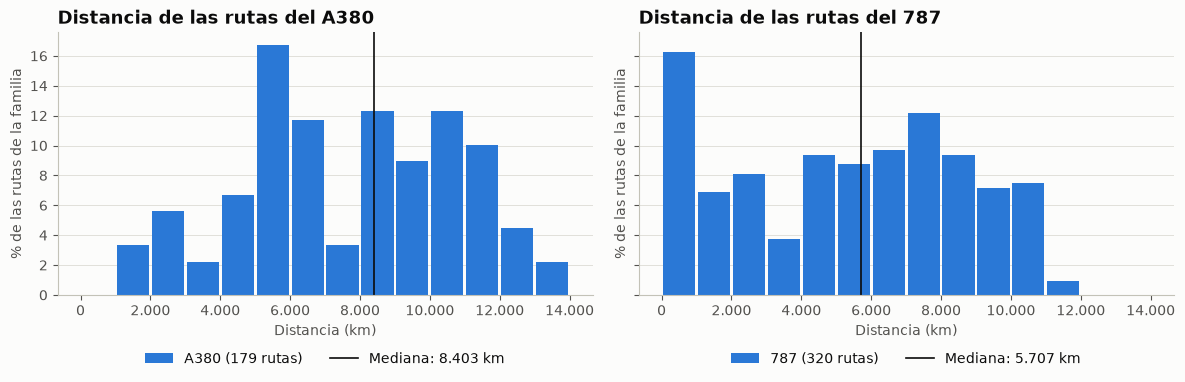

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4), sharex=True, sharey=True)
for eje, familia in zip(ejes, ["A380", "787"]):
    s = limpio.loc[limpio["familia"] == familia, "km"]
    eje.hist(s, bins=np.arange(0, 15000, 1000), weights=np.ones(len(s)) / len(s) * 100, color=AZUL, rwidth=0.92, label=f"{familia} ({len(s)} rutas)")
    eje.axvline(s.median(), color="#0b0b0b", linewidth=1.2, label=f"Mediana: {s.median():,.0f} km".replace(",", "."))
    eje.set(title=f"Distancia de las rutas del {familia}", xlabel="Distancia (km)", ylabel="% de las rutas de la familia")
    eje.xaxis.set_major_formatter(miles)
    eje.grid(axis="x", visible=False)
    eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=2)
fig.tight_layout()
guardar(fig, "comparacion_a380_787.png")

**Lo que muestra:** son dos perfiles distintos. Cerca del 18 % de las rutas del A380 mide menos de 5.000 km, y ninguna baja de 1.000 km. El 787, en cambio, tiene alrededor de un 16 % de rutas de menos de 1.000 km, además de muchas de largo alcance. La mediana del A380 supera a la del 787 en casi 2.700 km.

## 2.4 Valores atípicos (outliers)

Un boxplot resume la distribución: la caja contiene el 50 % central de las rutas, la línea interior es la mediana y los puntos sueltos son posibles outliers. Se usa la regla habitual: es atípico lo que queda a más de 1,5 veces el rango intercuartílico (IQR) de la caja.

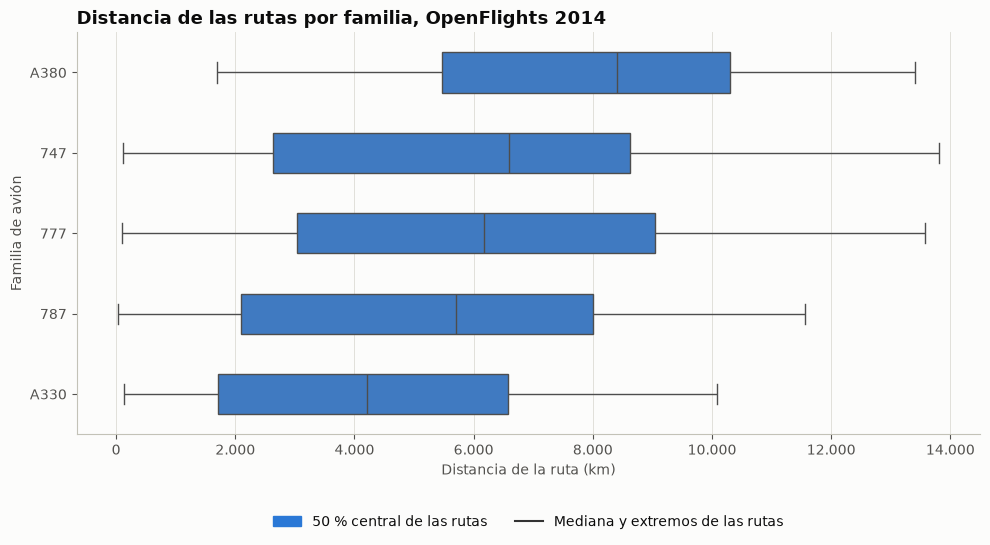

,q1,q3,limite_inferior,limite_superior,outliers_bajos,outliers_altos
familia,,,,,,
747,2633,8616,-6342,17591,0,0
777,3031,9042,-5986,18058,0,0
787,2096,8009,-6775,16880,0,0
A330,1704,6575,-5602,13881,0,0
A380,5473,10306,-1776,17554,0,0


Las 8 filas más largas:


,aerolinea,origen,destino,familia,km
4037,Qantas,SYD,DFW,747,13808.0
1740,Delta Air Lines,ATL,JNB,777,13583.0
1794,Delta Air Lines,JNB,ATL,777,13583.0
816,JetBlue Airways,DXB,LAX,A380,13400.0
824,JetBlue Airways,LAX,DXB,A380,13400.0
2034,Emirates,DXB,LAX,A380,13400.0
2128,Emirates,LAX,DXB,A380,13400.0
4714,Saudi Arabian Airlines,JED,LAX,777,13390.0


Las 8 filas más cortas:


,aerolinea,origen,destino,familia,km
2228,Ethiopian Airlines,FIH,BZV,787,26.0
833,British Airways,ANU,SKB,777,100.0
994,British Airways,SKB,ANU,777,100.0
433,Air France,DLA,SSG,777,116.0
500,Air France,SSG,DLA,777,116.0
530,Air India Limited,CCJ,COK,747,120.0
535,Air India Limited,COK,CCJ,747,120.0
1428,Cathay Pacific,CAN,HKG,A330,136.0


Aerolíneas con A380 en la base:


,rutas
aerolinea,
Emirates,56
Singapore Airlines,22
Lufthansa,16
Air France,14
Qantas,12
US Airways,10
Korean Air,8
Thai Airways International,8
British Airways,6


A380 con todas: 179 filas y mediana de 8.403 km | sin las dudosas: 150 filas y mediana de 7.764 km


In [ ]:
def caja_distancia(df, titulo, archivo, destacar=None):
    orden = df.groupby("familia")["km"].median().sort_values(ascending=False).index
    colores = {f: (NARANJA if f == destacar else AZUL) for f in orden}
    fig, eje = plt.subplots(figsize=(10, 0.8 * len(orden) + 1.6))
    sns.boxplot(data=df, x="km", y="familia", hue="familia", order=orden, hue_order=orden, palette=colores, legend=False, width=0.5, fliersize=2.5, linewidth=1, ax=eje)
    eje.set(title=titulo, xlabel="Distancia de la ruta (km)", ylabel="Familia de avión")
    eje.xaxis.set_major_formatter(miles)
    eje.grid(axis="y", visible=False)
    leyenda = [Patch(color=AZUL, label="50 % central de las rutas"), Line2D([], [], color="#333333", label="Mediana y extremos de las rutas")]
    if tabla_outliers(df)[["outliers_bajos", "outliers_altos"]].to_numpy().sum():
        leyenda.append(Line2D([], [], marker="o", color="none", markerfacecolor="#333333", markersize=3, label="Posibles outliers"))
    if destacar:
        leyenda.insert(1, Patch(color=NARANJA, label=f"50 % central, {destacar}"))
    eje.legend(handles=leyenda, loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=4)
    fig.tight_layout()
    guardar(fig, archivo)

def tabla_outliers(df):
    filas = []
    for familia, s in df.groupby("familia")["km"]:
        q1, q3 = s.quantile([0.25, 0.75])
        bajo, alto = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
        filas.append({"familia": familia, "q1": q1, "q3": q3, "limite_inferior": bajo, "limite_superior": alto, "outliers_bajos": (s < bajo).sum(), "outliers_altos": (s > alto).sum()})
    return pd.DataFrame(filas).set_index("familia").round(0).astype(int)

caja_distancia(limpio, "Distancia de las rutas por familia, OpenFlights 2014", "boxplot_openflights.png")
display(tabla_outliers(limpio))
cols = ["aerolinea", "origen", "destino", "familia", "km"]
print("Las 8 filas más largas:")
display(limpio.nlargest(8, "km")[cols].round(0))
print("Las 8 filas más cortas:")
display(limpio.nsmallest(8, "km")[cols].round(0))
print("Aerolíneas con A380 en la base:")
display(limpio[limpio["familia"] == "A380"]["aerolinea"].value_counts().rename("rutas").to_frame())

# Hasta donde sé, estas aerolíneas no operaban el A380: serían códigos compartidos sin marcar (supuesto mío, no sale de los datos).
A380_DUDOSAS = ["US Airways", "Delta Air Lines", "American Airlines", "JetBlue Airways", "Ethiopian Airlines", "Finnair"]
es_dudosa = (limpio["familia"] == "A380") & limpio["aerolinea"].isin(A380_DUDOSAS)
a380 = limpio[limpio["familia"] == "A380"]
print(f"A380 con todas: {len(a380)} filas y mediana de {a380['km'].median():,.0f} km | sin las dudosas: {len(a380) - es_dudosa.sum()} filas y mediana de {limpio.loc[(limpio['familia'] == 'A380') & ~es_dudosa, 'km'].median():,.0f} km".replace(",", "."))

**Resultado sorprendente: la regla del IQR no encuentra ningún outlier.** Las distancias de cada familia están tan repartidas que los límites quedan fuera de lo posible. Por ejemplo, el límite inferior es negativo y no existen distancias negativas. Por eso los boxplots no muestran puntos sueltos.

**Eso no significa que los datos no tengan errores,** así que reviso los extremos a mano:

- **La más larga:** Sídney–Dallas de Qantas con 747, 13.808 km. Es una distancia posible y se conserva.
- **La más corta:** Kinshasa–Brazzaville (`FIH`–`BZV`) con 787, 26 km. Son ciudades vecinas, a ambos lados del río Congo. Resulta llamativo para un widebody, pero no hay evidencia de que sea un error, así que se conserva.
- **Aerolíneas dudosas en el A380:** aparecen US Airways, Delta, American, JetBlue, Ethiopian y Finnair, que hasta donde sé no operaban este avión. Serían códigos compartidos sin marcar. Son 29 de las 179 filas (16,2 %).

Si se quitan esas 29 filas, la mediana del A380 baja de 8.403 a 7.764 km, pero sigue siendo la mayor. Se conservan en el análisis porque identificarlas depende de conocimiento externo, no de los datos. **Es probable que el mismo problema afecte a otras familias sin que pueda detectarlo.**

## 2.5 Hipótesis

Se plantean tres hipótesis y se revisan con los datos:

- **H1:** el 787 vuela rutas más largas que el A330.
- **H2:** el A380 vuela rutas más largas que el 787.
- **H3:** el 777 vuela rutas más largas que el 747.

**Cómo se comparan.** Una misma ruta aparece varias veces (ida, vuelta y varias aerolíneas), y eso haría parecer los datos más abundantes de lo que son. Por eso, para decidir se usa cada **par de aeropuertos una sola vez por familia**. Con esos pares se calcula la diferencia de medianas y un intervalo de confianza al 95 % por *bootstrap*: se remuestrean los datos 2.000 veces para ver cuánto varía el resultado.

- **Apoyada:** todo el intervalo es mayor que cero.
- **Contraria:** todo el intervalo es menor que cero.
- **No concluyente:** el intervalo incluye el cero.

In [ ]:
def agregar_par(df, a, b):
    df["par"] = np.where(df[a] < df[b], df[a] + "-" + df[b], df[b] + "-" + df[a])
    return df

def probar_hipotesis(df, comparaciones, repeticiones=2000):
    rng = np.random.default_rng(SEMILLA)
    pares = df.drop_duplicates(["familia", "par"])
    filas = []
    for a, b in comparaciones:
        x, y = (pares.loc[pares["familia"] == f, "km"].to_numpy() for f in (a, b))
        dif = np.median(rng.choice(x, (repeticiones, len(x))), axis=1) - np.median(rng.choice(y, (repeticiones, len(y))), axis=1)
        bajo, alto = np.percentile(dif, [2.5, 97.5])
        filas.append({
            "hipotesis": f"{a} > {b}",
            "mediana_filas_A": df.loc[df["familia"] == a, "km"].median(), "mediana_filas_B": df.loc[df["familia"] == b, "km"].median(),
            "media_filas_A": df.loc[df["familia"] == a, "km"].mean(), "media_filas_B": df.loc[df["familia"] == b, "km"].mean(),
            "pares_A": len(x), "pares_B": len(y), "mediana_pares_A": np.median(x), "mediana_pares_B": np.median(y),
            "dif_medianas_pares": np.median(x) - np.median(y), "ic95_bajo": bajo, "ic95_alto": alto,
            "resultado": "Apoyada" if bajo > 0 else ("Contraria" if alto < 0 else "No concluyente"),
        })
    return pd.DataFrame(filas).set_index("hipotesis").round(0)

limpio = agregar_par(limpio, "origen", "destino")
hip_of = probar_hipotesis(limpio, [("787", "A330"), ("A380", "787"), ("777", "747")])
display(hip_of.T)
print("Sensibilidad de H2 sin las aerolíneas dudosas del A380:")
display(probar_hipotesis(limpio[~es_dudosa], [("A380", "787")]).T)

hipotesis,787 > A330,A380 > 787,777 > 747
mediana_filas_A,5707.0,8403.0,6177.0
mediana_filas_B,4204.0,5707.0,6591.0
media_filas_A,5376.0,7686.0,6113.0
media_filas_B,4265.0,5376.0,5861.0
pares_A,146,70,775
pares_B,1081,146,247
mediana_pares_A,5537.0,7579.0,5909.0
mediana_pares_B,4382.0,5537.0,6569.0
dif_medianas_pares,1155.0,2041.0,-660.0
ic95_bajo,86.0,67.0,-1218.0


Sensibilidad de H2 sin las aerolíneas dudosas del A380:


hipotesis,A380 > 787
mediana_filas_A,7764.0
mediana_filas_B,5707.0
media_filas_A,7473.0
media_filas_B,5376.0
pares_A,70
pares_B,146
mediana_pares_A,7579.0
mediana_pares_B,5537.0
dif_medianas_pares,2041.0
ic95_bajo,57.0


**Revisión de las hipótesis:**

| Hipótesis | Medianas por pares | Diferencia e IC 95 % | Resultado |
|---|---|---|---|
| **H1:** 787 más largo que A330 | 5.537 y 4.382 km | +1.155 km (86 a 1.988) | Apoyada |
| **H2:** A380 más largo que 787 | 7.579 y 5.537 km | +2.041 km (67 a 3.936) | Apoyada |
| **H3:** 777 más largo que 747 | 5.909 y 6.569 km | −660 km (−1.218 a 213) | No concluyente |

- **H1 y H2 se apoyan, pero con margen estrecho:** el límite inferior de ambos intervalos está cerca de cero. En H2 hay solo 70 pares de A380, y el resultado se mantiene sin las aerolíneas dudosas (IC de 57 a 3.959).
- **H3 muestra por qué no basta con una medida:** por filas, la **media** favorece al 777 (6.113 frente a 5.861 km), pero la **mediana** favorece al 747 (6.177 frente a 6.591 km). Los datos no permiten afirmar que uno vuele más lejos que el otro.

El intervalo es aproximado y se hicieron varias comparaciones, así que un resultado con margen estrecho no debe tomarse como definitivo.

**Advertencia:** estos resultados describen *qué rutas tenía asignadas cada modelo en 2014*, no lo que cada avión es capaz de volar. Una ruta más corta no significa menos alcance: también depende de la demanda, la flota y las decisiones de cada aerolínea.

# Etapa 3: Visualización, modelo y storytelling

## 3.1 Rutas por modelo

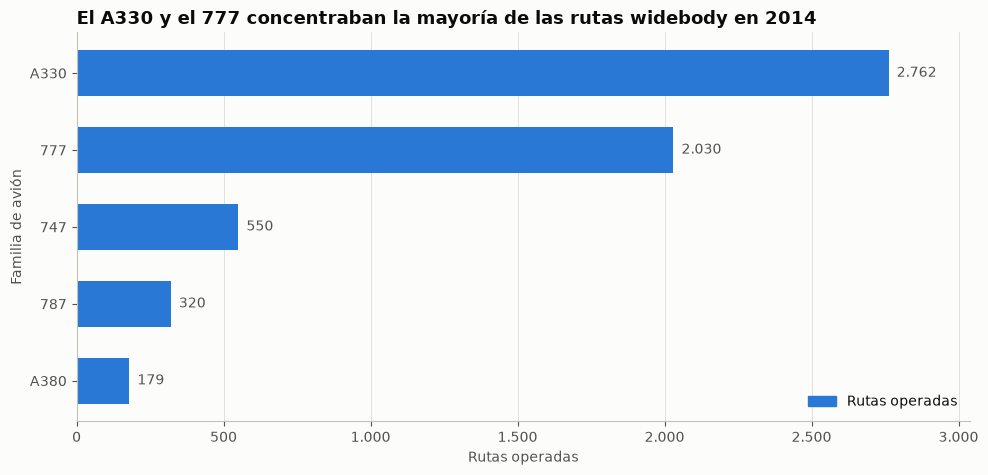

In [ ]:
def barras_rutas(df, titulo, archivo, etiqueta, destacar=None):
    conteo = df["familia"].value_counts().sort_values()
    fig, eje = plt.subplots(figsize=(10, 0.65 * len(conteo) + 1.6))
    eje.barh(conteo.index, conteo.values, height=0.6, color=[NARANJA if f == destacar else AZUL for f in conteo.index])
    for i, valor in enumerate(conteo.values):
        eje.text(valor + conteo.max() * 0.01, i, f"{valor:,}".replace(",", "."), va="center", color="#52514e")
    eje.set(title=titulo, xlabel=etiqueta, ylabel="Familia de avión", xlim=(0, conteo.max() * 1.1))
    eje.xaxis.set_major_formatter(miles)
    eje.grid(axis="y", visible=False)
    leyenda = [Patch(color=AZUL, label=etiqueta)] + ([Patch(color=NARANJA, label=f"{etiqueta}, {destacar}")] if destacar else [])
    eje.legend(handles=leyenda, loc="lower right")
    fig.tight_layout()
    guardar(fig, archivo)

barras_rutas(limpio, "El A330 y el 777 concentraban la mayoría de las rutas widebody en 2014", "barras_openflights.png", "Rutas operadas")

## 3.2 Distancia por modelo

El violín muestra la forma completa de la distribución: donde es más ancho, hay más rutas con esa distancia. A diferencia del boxplot, permite ver si una familia tiene dos grupos de rutas, por ejemplo uno regional y otro intercontinental.

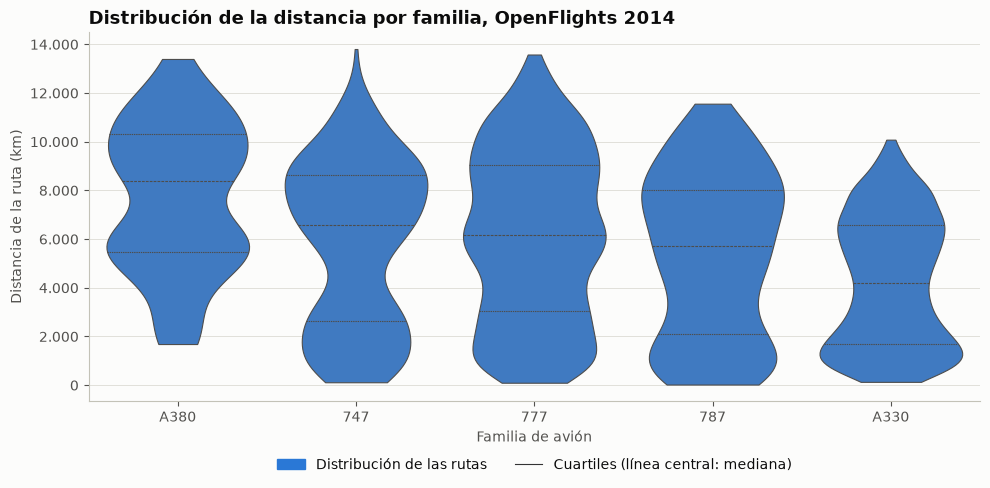

In [ ]:
def violin_distancia(df, titulo, archivo, destacar=None):
    orden = df.groupby("familia")["km"].median().sort_values(ascending=False).index
    colores = {f: (NARANJA if f == destacar else AZUL) for f in orden}
    fig, eje = plt.subplots(figsize=(10, 5))
    sns.violinplot(data=df, x="familia", y="km", hue="familia", order=orden, hue_order=orden, palette=colores, legend=False, cut=0, inner="quartile", linewidth=0.8, density_norm="width", ax=eje)
    eje.set(title=titulo, xlabel="Familia de avión", ylabel="Distancia de la ruta (km)")
    eje.yaxis.set_major_formatter(miles)
    eje.grid(axis="x", visible=False)
    leyenda = [Patch(color=AZUL, label="Distribución de las rutas"), Line2D([], [], color="#333333", linewidth=0.8, label="Cuartiles (línea central: mediana)")]
    if destacar:
        leyenda.insert(1, Patch(color=NARANJA, label=f"Distribución, {destacar}"))
    eje.legend(handles=leyenda, loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)
    fig.tight_layout()
    guardar(fig, archivo)

violin_distancia(limpio, "Distribución de la distancia por familia, OpenFlights 2014", "violin_openflights.png")

**Lo que muestra:** el A330, el 787, el 777 y el 747 tienen dos abultamientos, uno de rutas cortas por debajo de unos 2.000 km y otro de largo alcance. Esto significa que hay dos usos para el mismo tipo de avión, y que la media describe mal ambos. El A380 casi no tiene ese grupo corto: se concentra por encima de los 5.000 km.

## 3.3 Mapa de rutas

No uso un mapa de fondo para no añadir librerías: el contorno de los continentes se intuye con los aeropuertos de `airports.dat`, en gris. Las líneas son rectas en este plano, no el arco real que sigue el vuelo.

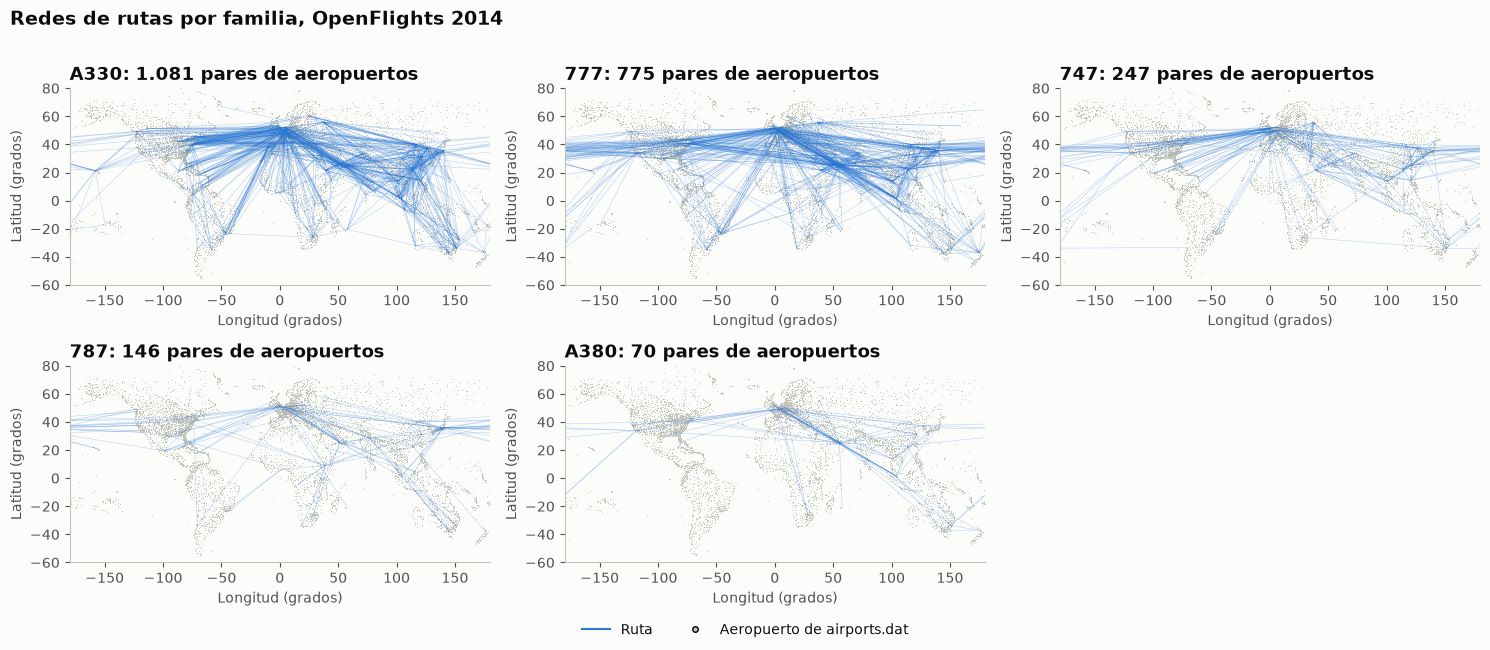

In [ ]:
def segmentos(df):
    lineas = []
    for lon1, lat1, lon2, lat2 in df[["longitud_origen", "latitud_origen", "longitud_destino", "latitud_destino"]].to_numpy():
        if abs(lon2 - lon1) <= 180:
            lineas.append([(lon1, lat1), (lon2, lat2)])
        else:  # La ruta cruza el meridiano 180: se parte en dos tramos para que no atraviese todo el mapa.
            borde = 180 if lon1 > 0 else -180
            lon2_ajustada = lon2 + 2 * borde
            lat_borde = lat1 + (lat2 - lat1) * (borde - lon1) / (lon2_ajustada - lon1)
            lineas += [[(lon1, lat1), (borde, lat_borde)], [(-borde, lat_borde), (lon2, lat2)]]
    return lineas

def mapa_rutas(df, titulo, archivo, destacar=None):
    orden = df["familia"].value_counts().index
    fig, ejes = plt.subplots(2, 3, figsize=(15, 6.5))
    for eje, familia in zip(ejes.flat, orden):
        unicas = df[df["familia"] == familia].drop_duplicates("par")
        color = NARANJA if familia == destacar else AZUL
        eje.scatter(aeropuertos["longitud"], aeropuertos["latitud"], s=0.4, color=GRIS, linewidths=0)
        eje.add_collection(LineCollection(segmentos(unicas), colors=color, linewidths=0.35, alpha=0.35))
        eje.set(title=f"{familia}: {len(unicas):,} pares de aeropuertos".replace(",", "."), xlim=(-180, 180), ylim=(-60, 80), xlabel="Longitud (grados)", ylabel="Latitud (grados)")
        eje.grid(False)
    for eje in list(ejes.flat)[len(orden):]:
        eje.axis("off")
    leyenda = [Line2D([], [], color=AZUL, label="Ruta"), Line2D([], [], marker="o", color="none", markerfacecolor=GRIS, markersize=4, label="Aeropuerto de airports.dat")]
    if destacar:
        leyenda.insert(1, Line2D([], [], color=NARANJA, label=f"Ruta del {destacar}"))
    fig.legend(handles=leyenda, loc="lower center", ncol=3)
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", fontsize=14)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    guardar(fig, archivo)

mapa_rutas(limpio, "Redes de rutas por familia, OpenFlights 2014", "mapa_openflights.png")

## 3.4 Principales aerolíneas por modelo

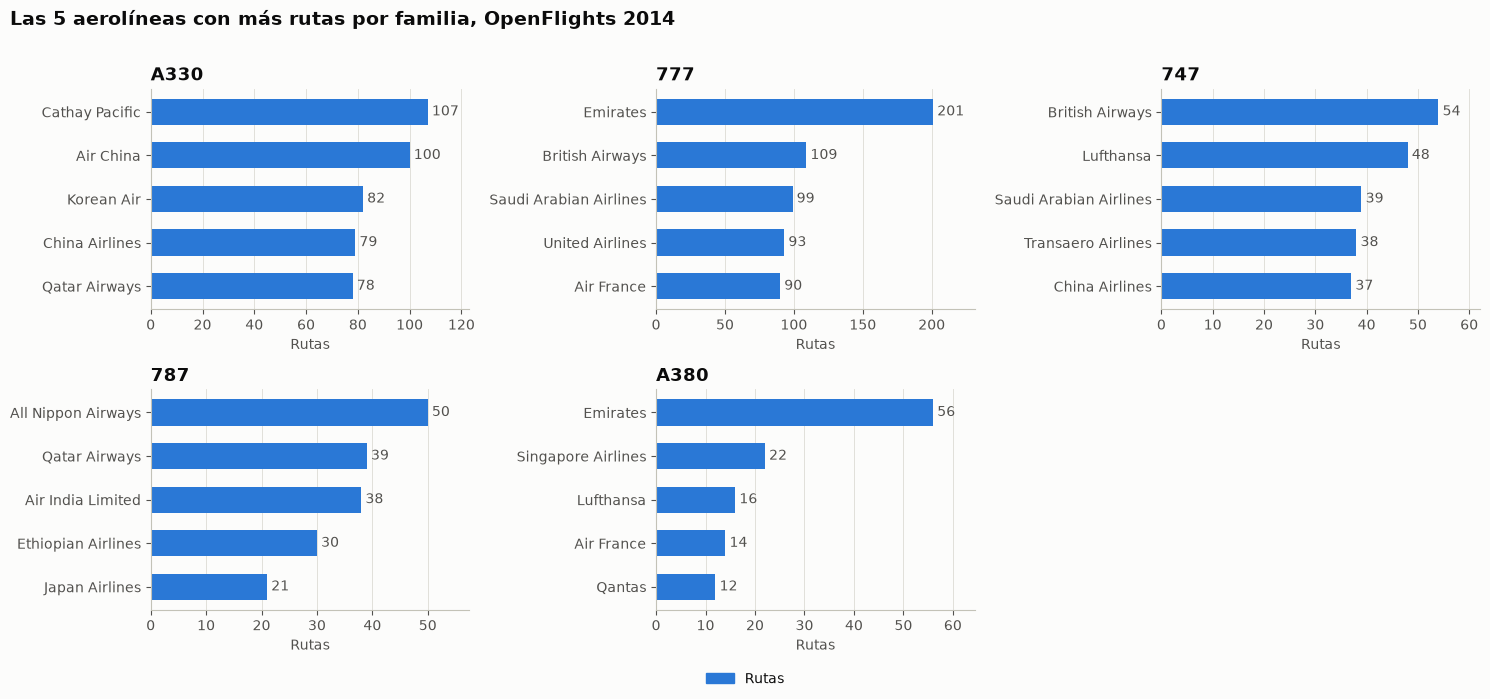

In [ ]:
def top_aerolineas(df, col, titulo, archivo, destacar=None, unidad="Rutas"):
    orden = df["familia"].value_counts().index
    fig, ejes = plt.subplots(2, 3, figsize=(15, 7))
    for eje, familia in zip(ejes.flat, orden):
        top = df[(df["familia"] == familia) & (df[col] != "Sin identificar")][col].value_counts().head(5).sort_values()
        eje.barh(top.index, top.values, height=0.6, color=NARANJA if familia == destacar else AZUL)
        for i, valor in enumerate(top.values):
            eje.text(valor + top.max() * 0.015, i, f"{valor:,}".replace(",", "."), va="center", color="#52514e")
        eje.set(title=familia, xlabel=unidad, xlim=(0, top.max() * 1.15))
        eje.xaxis.set_major_formatter(miles)
        eje.grid(axis="y", visible=False)
    for eje in list(ejes.flat)[len(orden):]:
        eje.axis("off")
    leyenda = [Patch(color=AZUL, label=unidad)] + ([Patch(color=NARANJA, label=f"{unidad}, {destacar}")] if destacar else [])
    fig.legend(handles=leyenda, loc="lower center", ncol=2)
    fig.suptitle(titulo, x=0.01, ha="left", fontweight="bold", fontsize=14)
    fig.tight_layout(rect=(0, 0.04, 1, 0.97))
    guardar(fig, archivo)

top_aerolineas(limpio, "aerolinea", "Las 5 aerolíneas con más rutas por familia, OpenFlights 2014", "aerolineas_openflights.png")

**Lo que muestran:**

- **Mapa:** las rutas forman corredores entre Europa, Oriente Medio, Asia y Norteamérica. El A330 y el 777 cubren casi todas las regiones, mientras que el A380 tiene una red mucho más limitada: 70 pares de aeropuertos frente a 1.081 del A330.
- **Aerolíneas:** Emirates lidera en dos familias, con 201 rutas de 777 y 56 de A380. En el A330 destacan aerolíneas asiáticas como Cathay Pacific (107) y Air China (100). All Nippon Airways encabeza el 787 con 50 rutas, y British Airways el 747 con 54.
- **Dependencia de pocos operadores:** en el A380, Emirates tiene 56 de las 179 filas (31 %). Lo que parece un rasgo del avión puede ser, en parte, la estrategia de una sola aerolínea.

## 3.5 Modelo predictivo: regresión lineal

**Objetivo:** predecir la distancia de una ruta a partir del tipo de avión y otras variables disponibles.

**Variables de entrada:**

- `familia`: tipo de avión, en codificación *one-hot* (una columna de 0 y 1 por familia).
- `region_origen` y `region_destino`: región de cada aeropuerto, tomada de su zona horaria (por ejemplo, `Asia` o `Europe`).
- `tipo_ruta`: doméstica o internacional.

**No se usan latitud y longitud a propósito.** La distancia se calcula con ellas, así que el modelo solo aprendería a reproducir la fórmula.

**División entrenamiento/prueba por par de aeropuertos.** Si la ida quedara en entrenamiento y la vuelta en prueba, el modelo ya habría visto casi la respuesta. Por eso, todas las filas de un mismo par quedan del mismo lado (`GroupShuffleSplit`), lo que da una evaluación más honesta.

**Tres modelos, de menos a más información:**

1. **Referencia:** predice siempre la media. Es el mínimo que cualquier modelo debería superar.
2. **Solo familia:** usa únicamente el tipo de avión.
3. **Completo:** añade región y tipo de ruta.

Entrenamiento: 4.680 filas | Prueba: 1.161 filas | Pares compartidos: 0
R² del modelo completo en validación cruzada de 5 partes: 0.386 ± 0.034


,R2,MAE_km,RMSE_km
modelo,,,
Referencia (media),-0.001,2871.495,3305.329
Solo familia,0.096,2722.033,3141.125
Completo,0.386,2069.918,2589.009


Coeficientes del modelo 'Solo familia' (km respecto al A330):


,km
familia_A380,3088.0
familia_777,1831.0
familia_747,1740.0
familia_787,997.0


Coeficientes de familia en el modelo completo (km respecto al A330):


,km
familia_A380,2375.0
familia_777,1606.0
familia_787,1142.0
familia_747,1133.0


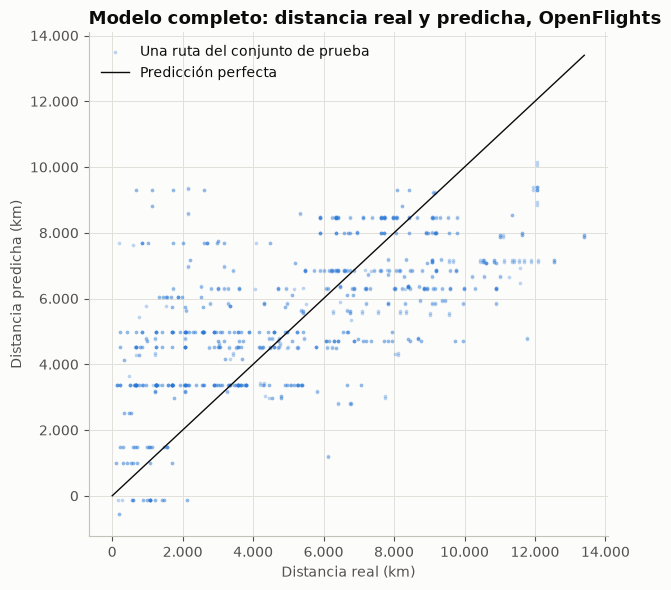

In [ ]:
REFERENCIAS = {"familia": "A330", "region_origen": "Europe", "region_destino": "Europe", "tipo_ruta": "Doméstica"}

def construir_modelo(df, columnas):
    categorias = [[REFERENCIAS[c]] + sorted(set(df[c]) - {REFERENCIAS[c]}) for c in columnas]
    codificador = ColumnTransformer([("onehot", OneHotEncoder(categories=categorias, drop="first", sparse_output=False), columnas)])
    return make_pipeline(codificador, LinearRegression())

def evaluar_modelos(df):
    completo = ["familia", "region_origen", "region_destino", "tipo_ruta"]
    entrena, prueba = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEMILLA).split(df, groups=df["par"]))
    tr, te = df.iloc[entrena], df.iloc[prueba]
    print(f"Entrenamiento: {len(tr):,} filas | Prueba: {len(te):,} filas | Pares compartidos: {len(set(tr['par']) & set(te['par']))}".replace(",", "."))
    modelos = {
        "Referencia (media)": (DummyRegressor(strategy="mean"), completo),
        "Solo familia": (construir_modelo(df, ["familia"]), ["familia"]),
        "Completo": (construir_modelo(df, completo), completo),
    }
    filas, ajustados = [], {}
    for nombre, (modelo, cols) in modelos.items():
        modelo.fit(tr[cols], tr["km"])
        p = modelo.predict(te[cols])
        ajustados[nombre] = (modelo, cols)
        filas.append({"modelo": nombre, "R2": r2_score(te["km"], p), "MAE_km": mean_absolute_error(te["km"], p), "RMSE_km": np.sqrt(mean_squared_error(te["km"], p))})
    metricas = pd.DataFrame(filas).set_index("modelo")
    r2_cv = cross_val_score(construir_modelo(df, completo), df[completo], df["km"], groups=df["par"], cv=GroupKFold(n_splits=5), scoring="r2")
    print(f"R² del modelo completo en validación cruzada de 5 partes: {r2_cv.mean():.3f} ± {r2_cv.std():.3f}")
    return metricas, ajustados, te

def coeficientes(modelo):
    nombres = modelo[0].get_feature_names_out()
    return pd.Series(modelo[-1].coef_, index=[n.replace("onehot__", "") for n in nombres])

def real_vs_predicho(modelo, cols, te, titulo, archivo):
    p = modelo.predict(te[cols])
    fig, eje = plt.subplots(figsize=(6.5, 6))
    eje.scatter(te["km"], p, s=7, alpha=0.3, color=AZUL, linewidths=0, label="Una ruta del conjunto de prueba")
    limite = [0, max(te["km"].max(), p.max())]
    eje.plot(limite, limite, color="#0b0b0b", linewidth=1, label="Predicción perfecta")
    eje.set(title=titulo, xlabel="Distancia real (km)", ylabel="Distancia predicha (km)")
    eje.xaxis.set_major_formatter(miles)
    eje.yaxis.set_major_formatter(miles)
    eje.legend(loc="upper left")
    fig.tight_layout()
    guardar(fig, archivo)

metricas_of, modelos_of, prueba_of = evaluar_modelos(limpio)
display(metricas_of.round(3))
modelo_completo, cols_completo = modelos_of["Completo"]
print("Coeficientes del modelo 'Solo familia' (km respecto al A330):")
display(coeficientes(modelos_of["Solo familia"][0]).round(0).sort_values(ascending=False).to_frame("km"))
print("Coeficientes de familia en el modelo completo (km respecto al A330):")
coef = coeficientes(modelo_completo)
display(coef[coef.index.str.startswith("familia")].round(0).sort_values(ascending=False).to_frame("km"))
real_vs_predicho(modelo_completo, cols_completo, prueba_of, "Modelo completo: distancia real y predicha, OpenFlights", "modelo_openflights.png")

**Qué significan las métricas:**

- **R²:** qué proporción de las diferencias de distancia entre rutas explica el modelo. 0 significa que no mejora a predecir la media; 1 sería perfecto.
- **MAE:** cuántos km se equivoca en promedio.
- **RMSE:** parecido al MAE, pero castiga más los errores grandes.

**Interpretación:**

| Modelo | R² | MAE | RMSE |
|---|---:|---:|---:|
| Referencia (media) | −0,001 | 2.871 km | 3.305 km |
| Solo familia | 0,096 | 2.722 km | 3.141 km |
| Completo | 0,386 | 2.070 km | 2.589 km |

- **El tipo de avión explica poco por sí solo:** el 9,6 % de las diferencias, y mejora el error apenas en 149 km frente a predecir siempre la media.
- **Saber la región y el tipo de ruta ayuda mucho más:** el R² llega a 0,386, un resultado estable en validación cruzada (0,386 ± 0,034).
- **Aun así el error es grande:** el modelo se equivoca en promedio unos 2.070 km. No sirve para predecir una ruta concreta.
- **Coeficientes:** manteniendo fijas región y tipo de ruta, el modelo asocia al A380 unos 2.375 km más que al A330, al 777 unos 1.606, al 787 unos 1.142 y al 747 unos 1.133.
- **El gráfico confirma los límites:** las predicciones forman bandas horizontales, porque rutas muy distintas comparten las mismas variables, y algunas predicciones son incluso negativas, algo imposible para una distancia.

**Limitaciones del modelo:**

- Una regresión lineal asume efectos que se suman, y la distancia no funciona exactamente así: el efecto de volar entre dos regiones depende de cuáles sean.
- Con estas variables no conoce la geografía exacta, el alcance del avión ni la demanda.
- Sirve para describir asociaciones, **no causas**: el avión no provoca la distancia, sino que las aerolíneas eligen un avión para cada ruta.
- Predecir la distancia es un ejercicio académico: en la práctica se calcula directamente con las coordenadas.

# Ampliación: el A350 con datos de OpenSky

## 4.1 Por qué hace falta otra fuente

OpenFlights no puede responder nada sobre el A350. **OpenSky Network** publica vuelos observados por una red colaborativa de antenas que reciben señales ADS-B de los aviones. Uso octubre de 2019, un mes anterior a la pandemia, de la versión con licencia [CC-BY 4.0](https://doi.org/10.5281/zenodo.5815448).

**Cómo se trabaja:** el archivo original pesa 242 MB, más de lo que admite GitHub. Por eso el repositorio incluye un extracto con solo los vuelos widebody, generado sin cambiar ningún valor por `datos/crear_extracto_opensky.py`.

**Importante:** todas las comparaciones con el A350 se hacen **dentro de OpenSky**. Las cifras de esta sección no se comparan con los conteos de OpenFlights.

In [ ]:
info = pd.read_json(DATOS + "opensky_extracto_info.json", typ="series")
opensky = pd.read_csv(DATOS + "opensky_widebody_2019_10.csv.gz", dtype=str, keep_default_na=False, na_values=[""])
print(f"Vuelos en el archivo original: {info['vuelos_totales']:,} | en el extracto: {len(opensky):,}".replace(",", "."))
print("% de vacíos en el archivo completo:", {k: v for k, v in info["pct_vacio_total"].items() if k in ("callsign", "typecode", "origin", "destination")})
opensky.info()
print("% de vacíos en el extracto:", (opensky.isna().mean() * 100).round(1).to_dict())
print("Duplicados exactos:", opensky.duplicated().sum())
FAMILIA_ICAO = {c: f for f, lista in info["typecodes_por_familia"].items() for c in lista}
opensky["familia"] = opensky["typecode"].map(FAMILIA_ICAO)
display(opensky["typecode"].value_counts().rename("vuelos").to_frame().assign(familia=lambda d: d.index.map(FAMILIA_ICAO)))

Vuelos en el archivo original: 2.946.779 | en el extracto: 181.980
% de vacíos en el archivo completo: {'callsign': 22.0, 'typecode': 26.6, 'origin': 27.1, 'destination': 21.1}
<class 'pandas.DataFrame'>
RangeIndex: 181980 entries, 0 to 181979
Data columns (total 15 columns):
 #   Column        Non-Null Count   Dtype
---  ------        --------------   -----
 0   callsign      172642 non-null  str  
 1   number        72174 non-null   str  
 2   aircraft_uid  181980 non-null  str  
 3   typecode      181980 non-null  str  
 4   origin        133129 non-null  str  
 5   destination   145152 non-null  str  
 6   firstseen     181980 non-null  str  
 7   lastseen      181980 non-null  str  
 8   day           181980 non-null  str  
 9   latitude_1    181980 non-null  str  
 10  longitude_1   181980 non-null  str  
 11  altitude_1    181980 non-null  str  
 12  latitude_2    181975 non-null  str  
 13  longitude_2   181975 non-null  str  
 14  altitude_2    170463 non-null  str  
dtypes: s

Duplicados exactos: 0


,vuelos,familia
typecode,,
A333,36292,A330
B77W,34355,777
A332,20861,A330
B772,18162,777
B788,14430,787
B744,12179,747
B789,10647,787
A388,10238,A380
B77L,8349,777


## 4.2 Limpieza de OpenSky

Estos datos tienen problemas distintos a los de OpenFlights:

| Problema detectado | Decisión | Por qué |
|---|---|---|
| Sin origen o destino | Quitar el vuelo | La red no vio el despegue o el aterrizaje, sobre todo en zonas sin antenas |
| Origen igual a destino | Quitar el vuelo | No hay ruta que medir |
| Aeropuerto que no está en `airports.dat` | Quitar el vuelo | Sin coordenadas no hay distancia |
| Más de 20 horas observadas | Quitar el vuelo | Se encontraron registros de hasta 42 horas, que probablemente unen varios vuelos |
| Velocidad aparente menor de 300 km/h | Quitar el vuelo | Un widebody en ruta va mucho más rápido: origen o destino probablemente erróneos |
| Menos de 100 km | Quitar el vuelo | Parecen traslados o errores de detección, como entre aeropuertos de una misma ciudad |
| Aerolínea de carga | Quitar el vuelo | Quiero comparar con pasajeros y el `typecode` no separa cargueros |

Los umbrales de 20 horas, 300 km/h y 100 km son **decisiones mías**, razonables pero no un estándar oficial.

La aerolínea se obtiene de las tres primeras letras del `callsign`, que se cruzan con el código ICAO de `airlines.dat`.

In [ ]:
aeropuertos_icao = aeropuertos.dropna(subset=["icao"]).drop_duplicates("icao")
ic = aeropuertos_icao[["icao", "aeropuerto_id"]]
paso = [("Vuelos widebody en el extracto", len(opensky))]

v = opensky.dropna(subset=["origin", "destination"]).copy()
paso.append(("Con origen y destino", len(v)))
v = v[v["origin"] != v["destination"]]
paso.append(("Origen distinto de destino", len(v)))

v = v.merge(ic.rename(columns={"icao": "origin", "aeropuerto_id": "id_o"}), on="origin").merge(ic.rename(columns={"icao": "destination", "aeropuerto_id": "id_d"}), on="destination")
v = con_aeropuertos(v, "id_o", "id_d")
paso.append(("Ambos aeropuertos en airports.dat", len(v)))

v = agregar_distancia(v)
v["horas"] = (pd.to_datetime(v["lastseen"]) - pd.to_datetime(v["firstseen"])).dt.total_seconds() / 3600
v["velocidad"] = v["km"] / v["horas"]
print("Máximo antes de filtrar:", round(v["km"].max()), "km y", round(v["horas"].max(), 1), "horas")

v = v[v["horas"] <= 20]
paso.append(("Hasta 20 horas observadas", len(v)))
v = v[v["velocidad"] >= 300]
paso.append(("Velocidad aparente de al menos 300 km/h", len(v)))
v = v[v["km"] >= 100]
paso.append(("Al menos 100 km", len(v)))

# Las aerolíneas activas tienen prioridad cuando un código ICAO aparece repetido.
nombres_icao = aerolineas.dropna(subset=["icao"]).sort_values("activa", ascending=False, kind="stable").drop_duplicates("icao").set_index("icao")
v["aerolinea_cod"] = v["callsign"].str[:3]
v["aerolinea"] = v["aerolinea_cod"].map(nombres_icao["nombre"]).fillna("Sin identificar")
v["pais_aerolinea"] = v["aerolinea_cod"].map(nombres_icao["pais"])
v["aerolinea_cod"] = v["aerolinea_cod"].fillna("SIN")

PATRON_CARGA = 'cargo|freight|parcel|federal express|logistic'
es_carga = v["aerolinea"].str.contains(PATRON_CARGA, case=False, regex=True)
print("Aerolíneas de carga quitadas (vuelos):")
display(v.loc[es_carga, ["aerolinea", "familia"]].value_counts().head(15).rename("vuelos").to_frame())
print("Vuelos de carga por familia:", v.loc[es_carga, "familia"].value_counts().to_dict())
v = v[~es_carga].copy()
paso.append(("Sin aerolíneas de carga", len(v)))

v = agregar_contexto(v)
v = agregar_par(v, "origin", "destination")
rutas_os = (v.groupby(["aerolinea_cod", "origin", "destination", "familia"], as_index=False)
            .agg(vuelos=("km", "size"), km=("km", "first"), aerolinea=("aerolinea", "first"), region_origen=("region_origen", "first"), region_destino=("region_destino", "first"),
                 tipo_ruta=("tipo_ruta", "first"), par=("par", "first"), longitud_origen=("longitud_origen", "first"), latitud_origen=("latitud_origen", "first"),
                 longitud_destino=("longitud_destino", "first"), latitud_destino=("latitud_destino", "first")))
paso.append(("Combinaciones aerolínea, ruta y familia", len(rutas_os)))
display(pd.DataFrame(paso, columns=["paso", "filas"]))

print("Máximo tras limpiar:", round(v["km"].max()), "km y", round(v["horas"].max(), 1), "horas")
print("Vuelos restantes con aerolínea sin identificar:", (v["aerolinea"] == "Sin identificar").sum())
print("747 restantes, 12 aerolíneas con más vuelos (revisión de carga no detectada):")
display(v[v["familia"] == "747"]["aerolinea"].value_counts().head(12).rename("vuelos").to_frame())

guardar_cols = ["callsign", "aerolinea", "typecode", "familia", "origin", "ciudad_origen", "pais_origen", "destination", "ciudad_destino", "pais_destino", "day", "horas", "km"]
v[guardar_cols].round({"horas": 2, "km": 1}).to_csv(SALIDA / "opensky_widebody_limpio.csv.gz", index=False, encoding="utf-8", compression={"method": "gzip", "mtime": 0})
print("Guardado:", SALIDA / "opensky_widebody_limpio.csv.gz", v[guardar_cols].shape)

Máximo antes de filtrar: 19604 km y 42.4 horas


Aerolíneas de carga quitadas (vuelos):


,,vuelos
aerolinea,familia,
Cargolux,747,762
Federal Express,777,678
United Parcel Service,747,651
AirBridge Cargo,747,585
Polar Air Cargo,747,290
Nippon Cargo Airlines,747,100
Air China Cargo,777,72
Lufthansa Cargo,777,69
China Cargo Airlines,747,63


Vuelos de carga por familia: {'747': 2531, '777': 859, 'A330': 1}


,paso,filas
0,Vuelos widebody en el extracto,181980
1,Con origen y destino,104273
2,Origen distinto de destino,100940
3,Ambos aeropuertos en airports.dat,94859
4,Hasta 20 horas observadas,94073
5,Velocidad aparente de al menos 300 km/h,93563
6,Al menos 100 km,93557
7,Sin aerolíneas de carga,90166
8,"Combinaciones aerolínea, ruta y familia",7518


Máximo tras limpiar: 14862 km y 20.0 horas
Vuelos restantes con aerolínea sin identificar: 5943
747 restantes, 12 aerolíneas con más vuelos (revisión de carga no detectada):


,vuelos
aerolinea,
British Airways,1224
Lufthansa,1097
China Airlines,1065
Sin identificar,997
Korean Air,542
Asiana Airlines,497
Atlas Air,449
Cathay Pacific,425
Singapore Airlines,301


Guardado: ..\datos\opensky_widebody_limpio.csv.gz (90166, 13)


**Lo que deja la limpieza:**

- **Se conserva cerca de la mitad:** de 181.980 vuelos quedan 90.166 (49,5 %). La mayor pérdida es la falta de origen o destino: 77.707 vuelos.
- **Los filtros físicos funcionan:** la distancia máxima baja de 19.604 a 14.862 km.
- **Se quitan 3.391 vuelos de aerolíneas de carga,** casi todos de 747 (2.531) y 777 (859).
- **Quedan cargueros sin detectar:** la búsqueda solo reconoce palabras en el nombre de la aerolínea. Atlas Air sigue con 449 vuelos de 747, hay 997 vuelos de 747 sin aerolínea identificada, y es posible que aerolíneas mixtas vuelen cargueros con su código de pasajeros. **Por eso el resultado del 747 es el menos confiable de esta sección.**
- **Sin aerolínea identificada:** 5.943 vuelos se conservan para la distancia, pero no entran en el ranking de aerolíneas.

## 4.3 Estadística descriptiva con las seis familias

Se presenta con la misma unidad que OpenFlights: una fila por **aerolínea, origen, destino y familia**. También se muestra la mediana **por vuelo**, porque una ruta diaria pesa lo mismo que una ruta vista una sola vez si solo se cuentan combinaciones.

,n,media,mediana,moda_100km,minimo,maximo,rango,varianza,desv_est,vuelos,mediana_por_vuelo,aerolineas
familia,,,,,,,,,,,,
A350,432,6882,7351,9600,205,13582,13377,11352798,3369,5064,6641,16
A380,302,6960,6344,5500,149,14201,14051,10011537,3164,7296,5834,13
787,1284,5874,5959,7700,104,14508,14404,11105381,3332,11998,5895,47
777,2264,5975,5907,9600,125,14862,14737,12865763,3587,34043,6033,55
747,1162,4862,4889,4600,150,12970,12820,8819063,2970,8520,6097,38
A330,2074,4562,4714,7100,106,13095,12989,8244775,2871,23245,4627,100


A380: Emirates tiene 54.9% de los vuelos | mediana de Emirates: 5498 km | mediana del resto: 8616 km


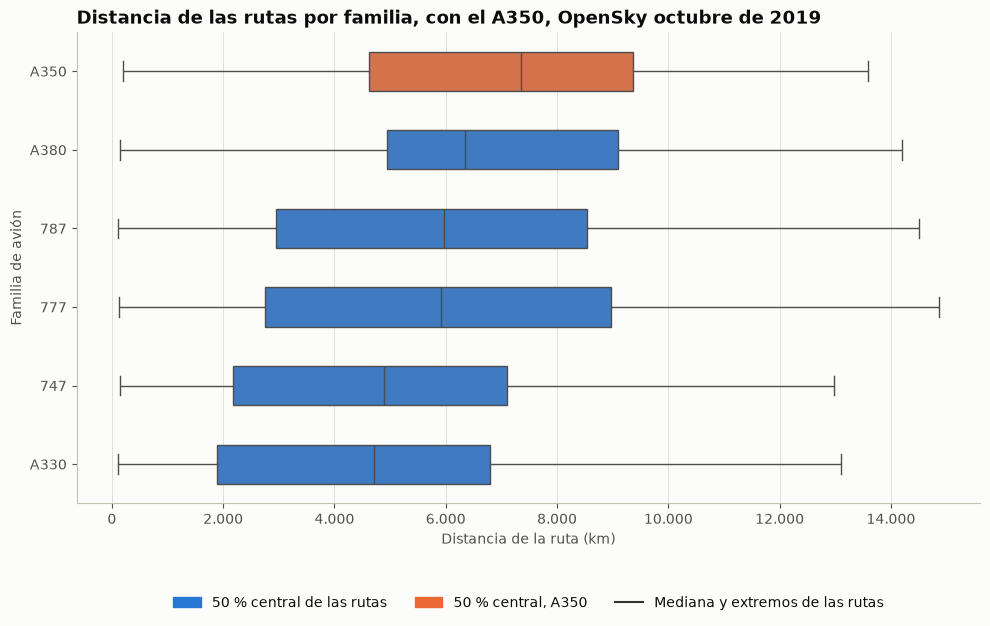

,q1,q3,limite_inferior,limite_superior,outliers_bajos,outliers_altos
familia,,,,,,
747,2170,7097,-5221,14488,0,0
777,2745,8962,-6582,18289,0,0
787,2947,8534,-5435,16915,0,0
A330,1889,6798,-5474,14161,0,0
A350,4618,9369,-2509,16497,0,0
A380,4943,9103,-1297,15342,0,0


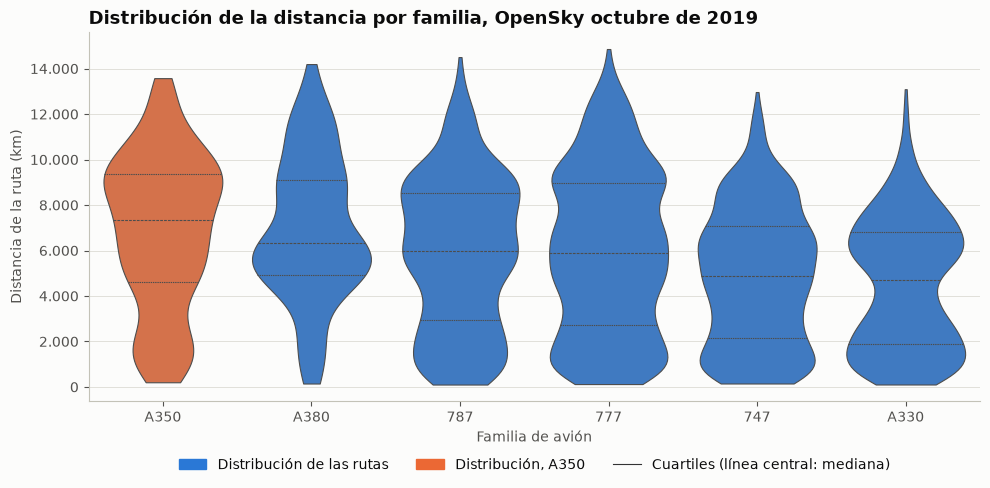

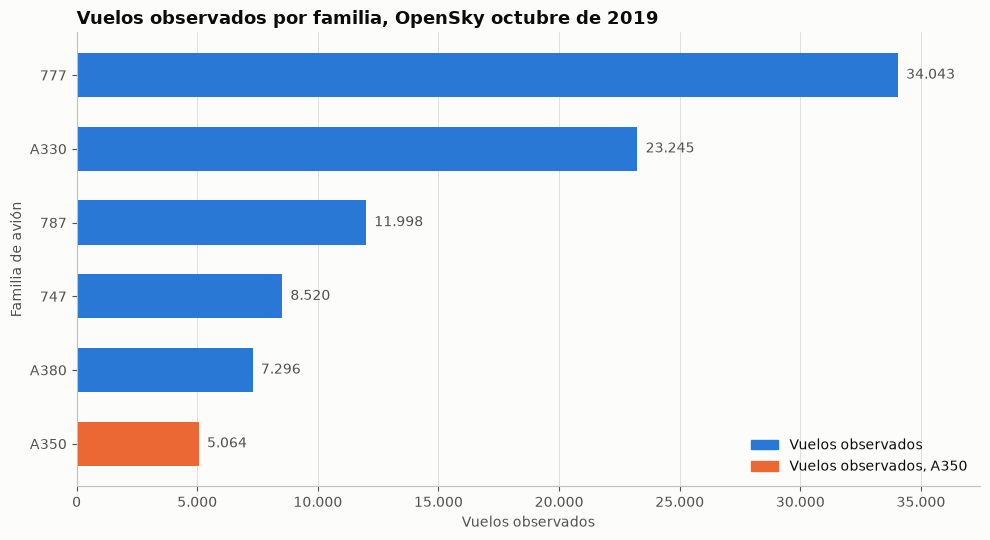

In [ ]:
est_os = estadisticos(rutas_os)
est_os["vuelos"] = v["familia"].value_counts()
est_os["mediana_por_vuelo"] = v.groupby("familia")["km"].median()
est_os["aerolineas"] = rutas_os[rutas_os["aerolinea"] != "Sin identificar"].groupby("familia")["aerolinea"].nunique()
display(est_os.round(0).astype(int))
vuelos_a380 = v[v["familia"] == "A380"]
de_emirates = vuelos_a380["aerolinea"] == "Emirates"
print(f"A380: Emirates tiene {de_emirates.mean():.1%} de los vuelos | mediana de Emirates: {vuelos_a380.loc[de_emirates, 'km'].median():.0f} km | mediana del resto: {vuelos_a380.loc[~de_emirates, 'km'].median():.0f} km")
caja_distancia(rutas_os, "Distancia de las rutas por familia, con el A350, OpenSky octubre de 2019", "boxplot_opensky.png", destacar="A350")
display(tabla_outliers(rutas_os))
violin_distancia(rutas_os, "Distribución de la distancia por familia, OpenSky octubre de 2019", "violin_opensky.png", destacar="A350")
barras_rutas(v, "Vuelos observados por familia, OpenSky octubre de 2019", "barras_opensky.png", "Vuelos observados", destacar="A350")

- **El A350 tiene la mediana más alta por ruta:** 7.351 km, seguido del A380 (6.344), el 787 (5.959), el 777 (5.907), el 747 (4.889) y el A330 (4.714).
- **También la tiene por vuelo:** 6.641 km. Sigue siendo el primero al dar más peso a las rutas frecuentes.
- **El A380 cambia mucho según cómo se mida:** es segundo por ruta, pero por vuelo cae al quinto lugar con 5.834 km. Emirates aporta el 55 % de sus vuelos, con una mediana de 5.498 km, frente a 8.616 km del resto.
- **El 747 hace lo contrario:** pasa de 4.889 km por ruta a 6.097 km por vuelo.
- **Outliers:** la regla del IQR vuelve a no encontrar ninguno.
- **Lectura correcta:** esto describe cómo se usaba cada avión ese mes, no su alcance máximo.

## 4.4 Hipótesis con el A350

- **H4:** el A350 vuela rutas más largas que el A330.
- **H5:** el A350 vuela rutas más largas que el 787.

También repito las tres hipótesis de OpenFlights con estos datos de 2019. Si una conclusión aparece en las dos fuentes, es más sólida; si cambia, puede deberse al paso del tiempo o a las diferencias entre las fuentes, y no puedo separar una causa de la otra.

In [ ]:
hip_os = probar_hipotesis(rutas_os, [("A350", "A330"), ("A350", "787"), ("787", "A330"), ("A380", "787"), ("777", "747")])
display(hip_os.T)

lado = pd.DataFrame({"mediana_OpenFlights_2014": limpio.groupby("familia")["km"].median(), "mediana_OpenSky_2019": rutas_os.groupby("familia")["km"].median()}).round(0)
print("Medianas por familia en cada fuente (son fuentes distintas: no leer como una tendencia):")
display(lado.sort_values("mediana_OpenSky_2019", ascending=False))

hipotesis,A350 > A330,A350 > 787,787 > A330,A380 > 787,777 > 747
mediana_filas_A,7351.0,7351.0,5959.0,6344.0,5907.0
mediana_filas_B,4714.0,5959.0,4714.0,5959.0,4889.0
media_filas_A,6882.0,6882.0,5874.0,6960.0,5975.0
media_filas_B,4562.0,5874.0,4562.0,5874.0,4862.0
pares_A,241,241,721,154,1245
pares_B,1151,721,1151,721,656
mediana_pares_A,7439.0,7439.0,6033.0,6413.0,5919.0
mediana_pares_B,5128.0,6033.0,5128.0,6033.0,4918.0
dif_medianas_pares,2312.0,1406.0,905.0,380.0,1001.0
ic95_bajo,1820.0,790.0,567.0,-201.0,494.0


Medianas por familia en cada fuente (son fuentes distintas: no leer como una tendencia):


,mediana_OpenFlights_2014,mediana_OpenSky_2019
familia,,
A350,NaN,7351.0
A380,8403.0,6344.0
787,5707.0,5959.0
777,6177.0,5907.0
747,6591.0,4889.0
A330,4204.0,4714.0


| Hipótesis (OpenSky 2019) | Medianas por pares | Diferencia e IC 95 % | Resultado |
|---|---|---|---|
| **H4:** A350 más largo que A330 | 7.439 y 5.128 km | +2.312 km (1.820 a 3.338) | Apoyada |
| **H5:** A350 más largo que 787 | 7.439 y 6.033 km | +1.406 km (790 a 2.337) | Apoyada |
| 787 más largo que A330 | 6.033 y 5.128 km | +905 km (567 a 1.558) | Apoyada |
| A380 más largo que 787 | 6.413 y 6.033 km | +380 km (−201 a 1.043) | No concluyente |
| 777 más largo que 747 | 5.919 y 4.918 km | +1.001 km (494 a 1.548) | Apoyada |

**Qué tan sólida es cada conclusión:**

- **La más sólida: 787 frente a A330.** Se apoya en las dos fuentes.
- **El A350 sale con ventaja clara,** pero solo hay un mes de datos y 16 aerolíneas identificadas.
- **Dos resultados cambian entre fuentes.** A380 frente a 787 pasa de apoyada a no concluyente, y 777 frente a 747 pasa de no concluyente a apoyada. El segundo debe leerse con cautela por los cargueros del 747. No sé si estos cambios se deben al paso del tiempo o a las diferencias entre fuentes.

## 4.5 Mapa y aerolíneas con el A350

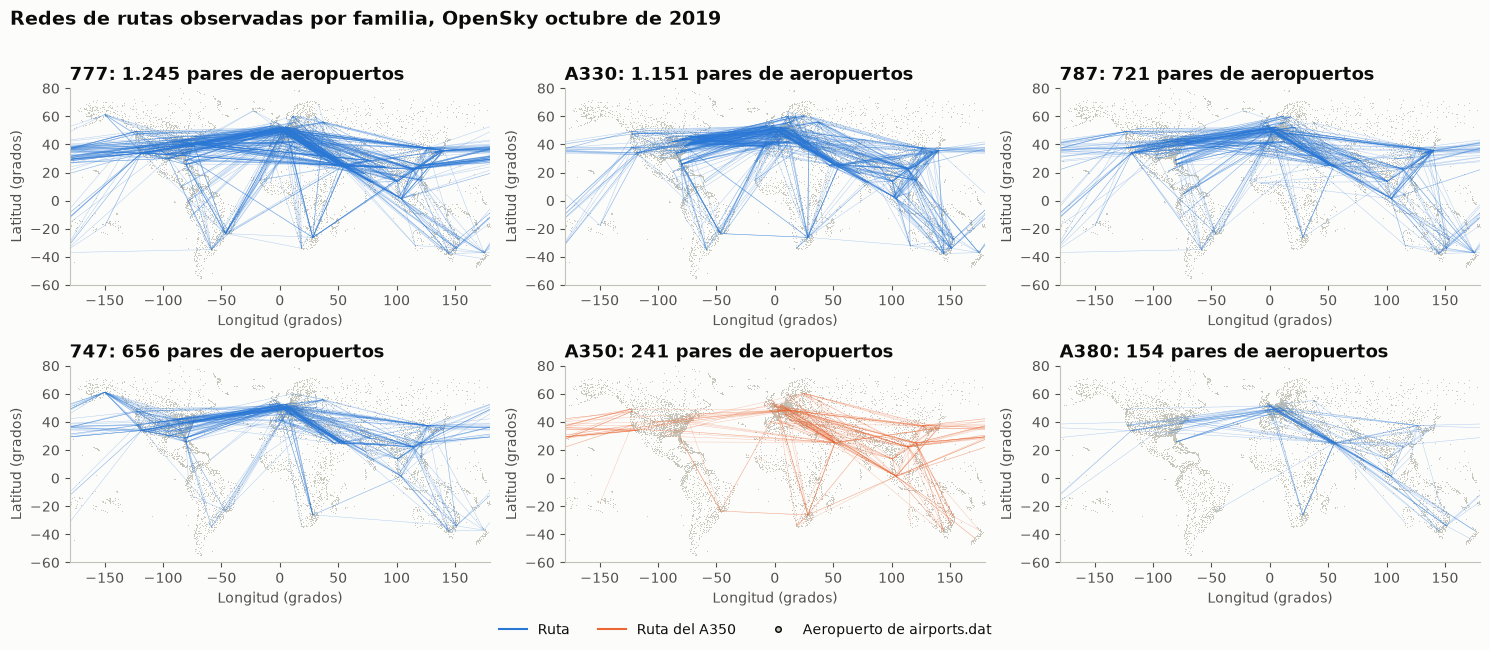

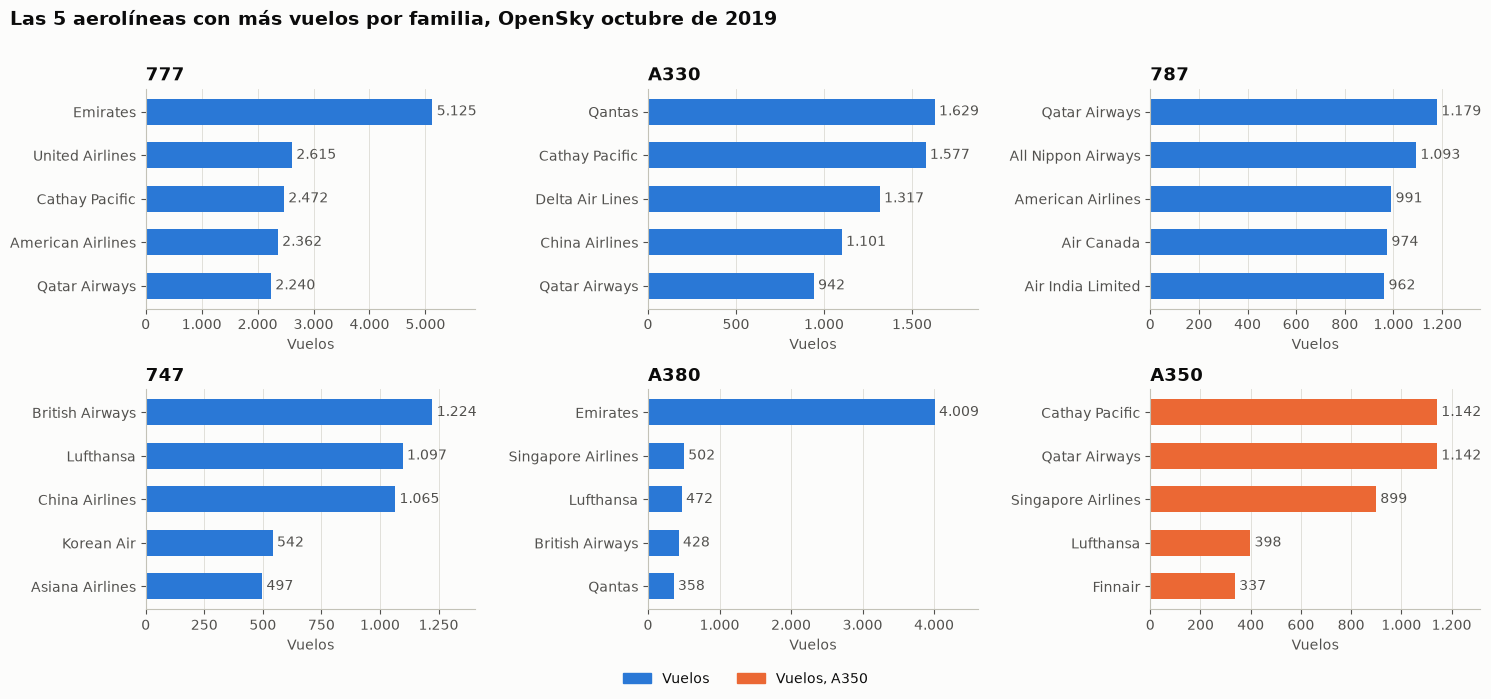

% de vuelos por región de origen:


region_origen,Africa,America,Asia,Atlantic,Australia,Europe,Pacific
familia,,,,,,,
747,1.5,36.6,32.2,0.0,1.9,27.6,0.2
777,1.1,25.9,46.2,0.1,2.7,22.8,1.1
787,0.9,25.3,40.0,0.0,4.1,27.0,2.7
A330,1.4,17.7,46.1,0.0,9.7,24.4,0.7
A350,4.4,10.4,53.5,0.0,5.1,24.9,1.7
A380,1.1,12.1,49.9,0.0,6.1,29.9,0.8


In [ ]:
mapa_rutas(rutas_os, "Redes de rutas observadas por familia, OpenSky octubre de 2019", "mapa_opensky.png", destacar="A350")
top_aerolineas(v, "aerolinea", "Las 5 aerolíneas con más vuelos por familia, OpenSky octubre de 2019", "aerolineas_opensky.png", destacar="A350", unidad="Vuelos")
regiones = pd.crosstab(v["familia"], v["region_origen"], normalize="index").mul(100).round(1)
print("% de vuelos por región de origen:")
display(regiones)

**Lo que muestran:**

- **El A350 es el avión más concentrado en Asia:** el 53,5 % de sus vuelos sale de allí, frente al 10,4 % de América. El 747, en cambio, tiene un 36,6 % en América.
- **Pocas aerolíneas lo explican:** Cathay Pacific (1.142 vuelos), Qatar Airways (1.142), Singapore Airlines (899), Lufthansa (398) y Finnair (337) suman el 77 % de los vuelos del A350.
- **El A380 depende aún más de una aerolínea:** Emirates tiene 4.009 de sus 7.296 vuelos.

**Precaución:** estos porcentajes también reflejan dónde tiene antenas OpenSky. Una región con pocas antenas parecerá tener menos vuelos de los que tiene en realidad.

## 4.6 Repetir el modelo incluyendo el A350

In [ ]:
metricas_os, modelos_os, prueba_os = evaluar_modelos(rutas_os)
display(metricas_os.round(3))
print("Coeficientes del modelo 'Solo familia' (km respecto al A330):")
display(coeficientes(modelos_os["Solo familia"][0]).round(0).sort_values(ascending=False).to_frame("km"))
print("Coeficientes de familia en el modelo completo (km respecto al A330):")
coef_os = coeficientes(modelos_os["Completo"][0])
display(coef_os[coef_os.index.str.startswith("familia")].round(0).sort_values(ascending=False).to_frame("km"))

Entrenamiento: 5.994 filas | Prueba: 1.524 filas | Pares compartidos: 0


R² del modelo completo en validación cruzada de 5 partes: 0.377 ± 0.021


,R2,MAE_km,RMSE_km
modelo,,,
Referencia (media),-0.001,2757.941,3339.019
Solo familia,0.049,2732.843,3254.434
Completo,0.430,2034.259,2520.199


Coeficientes del modelo 'Solo familia' (km respecto al A330):


,km
familia_A380,2607.0
familia_A350,2255.0
familia_777,1433.0
familia_787,1260.0
familia_747,340.0


Coeficientes de familia en el modelo completo (km respecto al A330):


,km
familia_A380,2331.0
familia_A350,2064.0
familia_777,1384.0
familia_787,1115.0
familia_747,588.0


| Modelo | R² | MAE | RMSE |
|---|---:|---:|---:|
| Referencia (media) | −0,001 | 2.758 km | 3.339 km |
| Solo familia | 0,049 | 2.733 km | 3.254 km |
| Completo | 0,430 | 2.034 km | 2.520 km |

- **La conclusión se repite con otra fuente:** el tipo de avión por sí solo explica muy poco (R² de 0,049), y añadir región y tipo de ruta mejora bastante.
- **Mejor cifra de referencia:** el R² de esta división es 0,430, pero en validación cruzada es 0,377 ± 0,021. Conviene citar este último, porque no depende de una sola división.
- **El A350 en el modelo:** con la misma región y tipo de ruta, se asocia a unos 2.064 km más que el A330. Solo el A380 queda por encima, con 2.331 km.

# Conclusiones

## Storytelling: la historia de los datos

**El punto de partida.** Quería saber cómo se usan los aviones que más me apasionan. Lo primero que encontré fue un problema: el A350, uno de los protagonistas, no tenía ni una sola ruta en la fuente principal. Ese vacío enseñó la primera lección: **antes de analizar hay que saber de cuándo son los datos**. La base terminó en junio de 2014.

**Primer acto: la foto de 2014.** Tras limpiar los datos quedaron 5.841 combinaciones de aerolínea, ruta y familia. El A330 y el 777 eran los más presentes, con el 82 % de las filas. El A380 era el más escaso y el de rutas más largas, con una mediana de 8.403 km frente a 4.204 km del A330.

**El giro: grande no siempre significa lejos.** Las distribuciones muestran dos usos: largo alcance y rutas cortas de pocos cientos de kilómetros. La moda del 787 es de apenas 400 km. Un widebody también puede servir para mover a muchos pasajeros en trayectos cortos.

**Segundo acto: aparece el A350.** Con 90.166 vuelos observados en octubre de 2019, el A350 mostró la mediana más alta, 7.351 km por ruta, y una fuerte presencia en Asia. La comparación entre el 787 y el A330 se repitió en las dos fuentes, pero la ventaja del A380 sobre el 787 dejó de ser concluyente. Parte de la explicación está en una sola aerolínea: Emirates aporta el 55 % de los vuelos del A380, en rutas más cortas que las del resto.

**El desenlace: el avión no decide solo.** El modelo lo resume bien. Conocer solo el tipo de avión explica menos del 10 % de las diferencias de distancia; al añadir región y tipo de ruta, cerca del 38 %. **La distancia de una ruta depende más de dónde se vuela que del avión,** y más de la mitad de las diferencias sigue sin explicarse con estas variables.

**Respuesta a la pregunta.** Los widebody se usan sobre todo en rutas internacionales entre grandes centros, pero no de forma uniforme. Cada familia tiene su perfil: el A380 y el A350 tienden al largo alcance, el A330 combina rutas regionales y largas, y el 777 está en todas partes. Ese perfil refleja tanto al avión como a la estrategia de las aerolíneas que lo operan.

## Aplicación profesional

Este mismo enfoque se podría usar en un trabajo de datos o sistemas. Por ejemplo, en el **área de análisis de flota y rutas de una aerolínea**:

1. **Integrar fuentes:** unir datos de horarios, aeropuertos y seguimiento de vuelos en una tabla confiable, con reglas de calidad documentadas como las de este notebook.
2. **Comparar con la competencia:** ver qué avión usan otras aerolíneas en una ruta o región, y a qué distancia suele operar cada modelo.
3. **Detectar oportunidades:** identificar rutas cuya distancia y región se salen de lo habitual para el avión asignado, como punto de partida para que el equipo de planificación las revise.
4. **Automatizar:** convertir este análisis en un proceso que se actualice solo y alimente un tablero.

Para decidir de verdad haría falta añadir datos que aquí no están, como ocupación, costos, frecuencias y consumo. También se podría aplicar en una **plataforma de viajes**, por ejemplo para dejar filtrar vuelos por tipo de avión, si se cuenta con datos actualizados.

## Limitaciones generales

- **Datos antiguos:** OpenFlights llega a junio de 2014 y OpenSky a octubre de 2019 en este análisis. Ninguno describe el uso actual.
- **Fuentes no comparables:** una lista rutas publicadas y la otra, vuelos observados. Sus conteos no se comparan y los cambios entre ellas no prueban una tendencia.
- **Un solo mes en OpenSky:** octubre no representa todas las temporadas.
- **Cobertura desigual:** OpenSky depende de antenas voluntarias y se pierde cerca de la mitad de los vuelos widebody en la limpieza. Lo que falta no es aleatorio.
- **Aeropuertos sin verificar:** OpenSky los calcula a partir de la trayectoria y advierte que no los contrasta con otras fuentes.
- **Cargueros y códigos compartidos residuales:** se filtraron los identificables, pero quedan casos sin detectar en ambas fuentes.
- **Una fila no es un vuelo en OpenFlights:** no indica la frecuencia. Una ruta diaria y otra semanal pesan igual.
- **Distancia teórica:** haversine da la distancia mínima, no la recorrida.
- **Decisiones propias:** los códigos de carga excluidos, las aerolíneas dudosas del A380 y los umbrales de limpieza son decisiones mías, explicadas en cada sección. Otras decisiones razonables podrían cambiar algunas cifras.

## Fuentes y licencias

- **OpenFlights:** [openflights.org/data.php](https://openflights.org/data.php), repositorio [jpatokal/openflights](https://github.com/jpatokal/openflights). Rutas hasta junio de 2014.
- **OpenSky Network:** *Crowdsourced air traffic data from The OpenSky Network 2020* [CC-BY], v21.12, Zenodo, [doi.org/10.5281/zenodo.5815448](https://doi.org/10.5281/zenodo.5815448). El extracto de este repositorio filtra el archivo de octubre de 2019.
- **Cita solicitada por el dataset:** Strohmeier, M., Olive, X., Lübbe, J., Schäfer, M. y Lenders, V. (2021). *Crowdsourced air traffic data from the OpenSky Network 2019–2020*. Earth System Science Data, 13(2), 357–366. [doi.org/10.5194/essd-13-357-2021](https://doi.org/10.5194/essd-13-357-2021).